<a href="https://colab.research.google.com/github/tongquangminh06052006-glitch/nh-m-2-ch-2-Logistics-v-QLCCU-CLC-66B-/blob/main/code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# PHẦN 1: GIAI ĐOẠN 1 - THIẾT LẬP MÔI TRƯỜNG, THU THẬP & ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU
# THIẾT LẬP MÔI TRƯỜNG, THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU
# ==============================================================================
import os
import io
import sys
import inspect
import warnings
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

import sklearn
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    balanced_accuracy_score, matthews_corrcoef, roc_curve, precision_recall_curve
)
from sklearn.inspection import permutation_importance

# Hàm hiệu chỉnh FDR Benjamini-Hochberg thuần NumPy
def multipletests(pvals, alpha=0.05, method='fdr_bh'):
    pvals = np.asarray(pvals, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked_p = pvals[order]
    adj = ranked_p * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    adj = np.clip(adj, 0.0, 1.0)
    pvals_corrected = np.empty(n, dtype=float)
    pvals_corrected[order] = adj
    reject = pvals_corrected <= alpha
    return reject, pvals_corrected, None, None

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

# Thiết lập Random Seed cố định
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Cấu hình hiển thị Pandas & Matplotlib
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', '{:.4f}'.format)

plt.rcParams['figure.figsize'] = (11, 5.5)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
sns.set_theme(style="whitegrid", palette="deep")
warnings.filterwarnings('ignore')

# Tạo thư mục lưu trữ kết quả đầu ra
OUTPUT_DIR = Path("outputs")
FIG_DIR = OUTPUT_DIR / "figures"
TAB_DIR = OUTPUT_DIR / "tables"
METRIC_DIR = OUTPUT_DIR / "metrics"
for directory in [FIG_DIR, TAB_DIR, METRIC_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("=" * 95)
print("KHỞI ĐỘNG DỰ ÁN MID-TERM 2 - NHÓM 2: BANK MARKETING DATASET (PYTHON 3)")
print("=" * 95)

# ------------------------------------------------------------------------------
# 1.2. THU THẬP DỮ LIỆU TỪ CÁC ĐƯỜNG LINK GITHUB
# ------------------------------------------------------------------------------
# Danh sách tất cả các biến thể đường dẫn từ 2 link GitHub
CANDIDATE_GITHUB_URLS = [
    # 1. Link GitHub Nhóm 2
    "https://github.com/hlinhhochoc/Nh-m-2---Topic-2---L-p-Logistics-v-QLCCU-CLC-66B---TOKT1138-126-CLC_57/blob/main/bank.csv",
    "https://raw.githubusercontent.com/hlinhhochoc/Nh-m-2---Topic-2---L-p-Logistics-v-QLCCU-CLC-66B---TOKT1138-126-CLC_57/main/bank.csv",
    "https://github.com/hlinhhochoc/Nh-m-2---Topic-2---L-p-Logistics-v-QLCCU-CLC-66B---TOKT1138-126-CLC_57/raw/refs/heads/main/bank.csv",
    # 2. Link GitHub cá nhân
    "https://github.com/tongquangminh06052006-glitch/nh-m-2-Logistics-v-QLCCU-CLC-66B-/blob/main/bank.csv",
    "https://raw.githubusercontent.com/tongquangminh06052006-glitch/nh-m-2-Logistics-v-QLCCU-CLC-66B-/main/bank.csv",
    "https://github.com/tongquangminh06052006-glitch/nh-m-2-Logistics-v-QLCCU-CLC-66B-/raw/refs/heads/main/bank.csv",
    "https://raw.githubusercontent.com/tongquangminh06052006-glitch/nh-m-2-Logistics-v-QLCCU-CLC-66B-/master/bank.csv"
]

def to_raw_github_url(url):
    """Tự động chuyển đổi link GitHub chứa '/blob/' sang link Raw tải file trực tiếp."""
    url = url.strip()
    if "github.com" in url and "/blob/" in url:
        return url.replace("github.com", "raw.githubusercontent.com").replace("/blob/", "/")
    return url

def read_csv_auto_sep(raw_bytes):
    """Đọc CSV và xác nhận bộ dữ liệu Bank Marketing."""
    text_sample = raw_bytes[:4096].decode('utf-8', errors='replace')
    first_line = text_sample.splitlines()[0] if text_sample.splitlines() else ""
    if "<!DOCTYPE html>" in text_sample or "<html" in text_sample.lower():
        raise ValueError("Nguồn dữ liệu trả về HTML thay vì tệp CSV.")
    sep = ';' if first_line.count(';') > first_line.count(',') else ','
    df_temp = pd.read_csv(io.BytesIO(raw_bytes), sep=sep)
    df_temp.columns = [str(c).strip() for c in df_temp.columns]
    required = {
        'age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
        'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
        'previous', 'poutcome'
    }
    missing = sorted(required.difference(df_temp.columns))
    if df_temp.empty or missing or not ({'deposit', 'y'} & set(df_temp.columns)):
        raise ValueError(
            f"CSV không đúng cấu trúc Bank Marketing (shape={df_temp.shape}, "
            f"thiếu cột={missing}, có biến đích={'deposit' in df_temp.columns or 'y' in df_temp.columns})."
        )
    return df_temp, sep

def load_bank_dataset_robust(url_list, local_filename="bank.csv"):
    """Nạp dữ liệu từ bản cục bộ trước, rồi sau đó thử các URL Raw trên GitHub."""
    local_candidates = [Path(local_filename), Path("outputs") / local_filename]
    checked = set()
    for local_path in local_candidates:
        if str(local_path.resolve()) in checked:
            continue
        checked.add(str(local_path.resolve()))
        if local_path.exists():
            print(f"[Nguồn cục bộ] Đang đọc '{local_path}'.")
            raw_bytes = local_path.read_bytes()
            df_loaded, sep = read_csv_auto_sep(raw_bytes)
            print(f" -> Kích thước: {len(raw_bytes)/1024:.2f} KB | Dấu phân cách: '{sep}' | Số dòng: {len(df_loaded):,}")
            return df_loaded, str(local_path.resolve())

    headers = {'User-Agent': 'Mozilla/5.0'}
    raw_urls = []
    for url in url_list:
        raw_url = to_raw_github_url(url)
        if raw_url not in raw_urls:
            raw_urls.append(raw_url)

    for idx, url in enumerate(raw_urls, start=1):
        try:
            print(f"[Thử kết nối {idx}/{len(raw_urls)}] Đang lấy dữ liệu từ:\n -> {url}")
            req = urllib.request.Request(url, headers=headers)
            # Giữ xác minh chứng chỉ TLS mặc định của Python.
            with urllib.request.urlopen(req, timeout=20) as resp:
                raw_bytes = resp.read()
            df_loaded, sep = read_csv_auto_sep(raw_bytes)
            Path(local_filename).write_bytes(raw_bytes)
            print(f" -> THÀNH CÔNG! Kích thước: {len(raw_bytes)/1024:.2f} KB | Dấu phân cách: '{sep}' | Số dòng: {len(df_loaded):,}")
            return df_loaded, url
        except Exception as e:
            print(f" -> Không lấy được từ link {idx} ({e}). Chuyển sang link tiếp theo...")

    print("\nKhông tải được từ GitHub. Hãy chọn đúng tệp bank.csv để tiếp tục:")
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("Chưa chọn tệp bank.csv.")
    first_key = list(uploaded.keys())[0]
    raw_bytes = uploaded[first_key]
    df_loaded, sep = read_csv_auto_sep(raw_bytes)
    Path(local_filename).write_bytes(raw_bytes)
    return df_loaded, f"Google Colab Upload ({first_key})"

# Thực thi tải dữ liệu
df_raw, data_source_used = load_bank_dataset_robust(CANDIDATE_GITHUB_URLS)
df_raw.columns = [str(c).strip() for c in df_raw.columns]
df = df_raw.copy()

TARGET_COL = 'deposit' if 'deposit' in df.columns else 'y'
if TARGET_COL not in df.columns:
    raise ValueError("Không tìm thấy biến mục tiêu 'deposit' hoặc 'y'.")
print(f"\n=== XÁC NHẬN DỮ LIỆU ĐẦU VÀO ===")
print(f"- Nguồn dữ liệu sử dụng : {data_source_used}")
print(f"- Kích thước tập dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"- Biến mục tiêu         : '{TARGET_COL}'\n")

# ------------------------------------------------------------------------------
# 1.3. XÂY DỰNG BẢNG TỪ ĐIỂN DỮ LIỆU (DATA DICTIONARY)
# ------------------------------------------------------------------------------
variable_metadata = {
    'age': ('Demographic', 'Độ tuổi khách hàng (năm).', 'Phân khúc theo vòng đời tài chính và nhu cầu tích lũy.'),
    'job': ('Demographic', 'Nghề nghiệp khách hàng.', 'Đánh giá tính ổn định thu nhập và hành vi tiết kiệm.'),
    'marital': ('Demographic', 'Tình trạng hôn nhân.', 'Phản ánh trách nhiệm tài chính gia đình.'),
    'education': ('Demographic', 'Trình độ học vấn.', 'Liên quan đến nhận thức tài chính và tiếp nhận sản phẩm.'),
    'default': ('Financial', 'Tình trạng nợ xấu tín dụng (yes/no).', 'Chỉ báo rủi ro tín dụng cốt lõi.'),
    'balance': ('Financial', 'Số dư tài khoản trung bình năm.', 'Thước đo lượng tiền nhàn rỗi có thể gửi tiết kiệm.'),
    'housing': ('Financial', 'Khoản vay mua nhà (yes/no).', 'Đánh giá áp lực trả nợ dài hạn.'),
    'loan': ('Financial', 'Khoản vay tiêu dùng cá nhân (yes/no).', 'Phản ánh áp lực tài chính ngắn hạn.'),
    'contact': ('Marketing Campaign', 'Phương thức liên lạc (cellular, telephone, unknown).', 'Đánh giá hiệu quả kênh tiếp cận.'),
    'day': ('Marketing Campaign', 'Ngày liên hệ cuối cùng trong tháng (1-31).', 'Phân tích thời điểm gọi trong tháng.'),
    'month': ('Marketing Campaign', 'Tháng liên hệ cuối cùng trong năm.', 'Phân tích tính mùa vụ của chiến dịch.'),
    'duration': ('Marketing Campaign', 'Thời lượng cuộc gọi cuối cùng (giây).', 'Chỉ biết sau cuộc gọi (Gây Data Leakage nếu dùng dự đoán trước cuộc gọi).'),
    'campaign': ('Marketing Campaign', 'Số lần liên hệ trong chiến dịch hiện tại.', 'Đo lường cường độ gọi và quy luật lợi suất giảm dần.'),
    'pdays': ('Previous Campaign', 'Số ngày từ lần liên hệ ở chiến dịch trước (-1 = chưa từng liên hệ).', 'Đánh giá độ trễ và lịch sử tiếp xúc.'),
    'previous': ('Previous Campaign', 'Số lần liên hệ trước chiến dịch này.', 'Đo lường tần suất tương tác quá khứ.'),
    'poutcome': ('Previous Campaign', 'Kết quả chiến dịch trước (success, failure, other, unknown).', 'Chỉ báo lịch sử phản hồi thực tế.'),
    'deposit': ('Target Variable', 'Khách hàng có đăng ký tiền gửi có kỳ hạn không (yes/no).', 'Biến mục tiêu cần phân tích và dự báo.'),
    'y': ('Target Variable', 'Khách hàng có đăng ký tiền gửi có kỳ hạn không (yes/no).', 'Biến mục tiêu cần phân tích và dự báo.')
}

dict_rows = []
for col in df.columns:
    group, desc, biz_meaning = variable_metadata.get(
        col, ('Other', 'Diễn giải từ tên biến và cấu trúc dữ liệu.', 'Cần kiểm tra phân phối thực tế.')
    )
    sample_vals = df[col].dropna().unique()[:5]
    dict_rows.append({
        'Tên biến': col,
        'Kiểu dữ liệu': str(df[col].dtype),
        'Số giá trị duy nhất': int(df[col].nunique()),
        'Nhóm biến': group,
        'Mô tả': desc,
        'Ý nghĩa kinh doanh': biz_meaning,
        'Giá trị mẫu': ", ".join(map(str, sample_vals))
    })

df_data_dictionary = pd.DataFrame(dict_rows)
df_data_dictionary.to_csv(TAB_DIR / "table_1_1_data_dictionary.csv", index=False)
print("=== 1.3. BẢNG TỪ ĐIỂN DỮ LIỆU (DATA DICTIONARY) ===")
display(df_data_dictionary)

# ------------------------------------------------------------------------------
# 1.4, 1.5, 1.6 & 1.7. KIỂM TRA CẤU TRÚC, MISSING, UNKNOWN, MÃ -1 & DUPLICATES
# ------------------------------------------------------------------------------
print("\n=== 1.4. KIỂM TRA 5 DÒNG ĐẦU & 5 DÒNG CUỐI ===")
display(df.head())
display(df.tail())

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in df.columns if c not in numeric_cols]
feature_cat_cols = [c for c in categorical_cols if c != TARGET_COL]

for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip()
    df_raw[col] = df_raw[col].astype(str).str.strip()

print("\n--- Thống kê mô tả biến định lượng (Numeric Features) ---")
desc_num = df[numeric_cols].describe().T
desc_num['median'] = df[numeric_cols].median()
desc_num['IQR'] = desc_num['75%'] - desc_num['25%']
desc_num['skewness'] = df[numeric_cols].skew()
display(desc_num)

print("\n--- Thống kê mô tả biến định tính (Categorical Features) ---")
display(df[categorical_cols].describe().T)

target_vc = df[TARGET_COL].value_counts()
target_prop = df[TARGET_COL].value_counts(normalize=True) * 100
target_summary_str = " | ".join([f"{k}: {target_vc[k]:,} ({target_prop[k]:.2f}%)" for k in target_vc.index])

quality_summary = pd.DataFrame([
    {'Tiêu chí': 'Tổng số dòng', 'Kết quả': f"{df.shape[0]:,}", 'Nhận xét': 'Quy mô mẫu đủ lớn cho kiểm định thống kê và Machine Learning.'},
    {'Tiêu chí': 'Tổng số cột', 'Kết quả': f"{df.shape[1]}", 'Nhận xét': f"Gồm {df.shape[1]-1} biến độc lập và 1 biến mục tiêu ('{TARGET_COL}')."},
    {'Tiêu chí': 'Missing values (NaN chuẩn)', 'Kết quả': f"{int(df_raw.isnull().sum().sum()):,}", 'Nhận xét': 'Số lượng ô trống NaN trực tiếp trong file gốc.'},
    {'Tiêu chí': 'Duplicate rows (Trùng hoàn toàn)', 'Kết quả': f"{int(df_raw.duplicated().sum()):,}", 'Nhận xét': 'Số bản ghi trùng lặp trên tất cả các cột.'},
    {'Tiêu chí': 'Numeric features', 'Kết quả': f"{len(numeric_cols)} ({', '.join(numeric_cols)})", 'Nhận xét': 'Các biến định lượng.'},
    {'Tiêu chí': 'Categorical features', 'Kết quả': f"{len(feature_cat_cols)} ({', '.join(feature_cat_cols)})", 'Nhận xét': 'Các biến phân loại độc lập.'},
    {'Tiêu chí': f"Target distribution ('{TARGET_COL}')", 'Kết quả': target_summary_str, 'Nhận xét': 'Phân phối hai lớp của biến mục tiêu.'}
])
quality_summary.to_csv(TAB_DIR / "table_1_2_initial_quality_summary.csv", index=False)
print("\n--- Bảng tổng hợp chất lượng dữ liệu ban đầu ---")
display(quality_summary)

missing_audit_rows = []
n_total = len(df)
for col in df.columns:
    nan_cnt = int(df_raw[col].isnull().sum())
    if col in categorical_cols:
        s_clean = df[col].astype(str).str.strip().str.lower()
        blank_cnt = int((s_clean == '').sum())
        unknown_cnt = int((s_clean == 'unknown').sum())
        minus_one_cnt = int((s_clean == '-1').sum())
    else:
        blank_cnt = 0
        unknown_cnt = 0
        minus_one_cnt = int((df[col] == -1).sum())

    missing_audit_rows.append({
        'Tên biến': col,
        'Kiểu dữ liệu': str(df[col].dtype),
        'Số lượng NaN': nan_cnt,
        'Tỷ lệ NaN (%)': (nan_cnt / n_total) * 100.0,
        'Chuỗi rỗng (Blank)': blank_cnt,
        'Giá trị "unknown"': unknown_cnt,
        'Tỷ lệ "unknown" (%)': (unknown_cnt / n_total) * 100.0,
        'Mã đặc biệt (-1)': minus_one_cnt,
        'Tỷ lệ (-1) (%)': (minus_one_cnt / n_total) * 100.0
    })

df_missing_audit = pd.DataFrame(missing_audit_rows)
df_missing_audit.to_csv(TAB_DIR / "table_1_3_missing_unknown_audit.csv", index=False)
print("\n=== 1.5. BẢNG PHÂN BIỆT RÕ: NaN vs BLANK vs UNKNOWN vs MÃ ĐẶC BIỆT (-1) ===")
display(df_missing_audit)

dup_exact_count = int(df.duplicated().sum())
profile_cols = [c for c in ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan'] if c in df.columns]
dup_profile_count = int(df.duplicated(subset=profile_cols).sum())
print(f"\n=== 1.6. KIỂM TRA DỮ LIỆU TRÙNG LẶP ===")
print(f"- Số dòng trùng lặp hoàn toàn trên mọi cột : {dup_exact_count:,} dòng ({dup_exact_count/n_total*100:.4f}%)")
print(f"- Số dòng trùng hồ sơ nhân khẩu học cơ bản : {dup_profile_count:,} dòng ({dup_profile_count/n_total*100:.2f}%) -> Giữ nguyên vì không có cột Customer_ID.")

KHỞI ĐỘNG DỰ ÁN MID-TERM 2 - NHÓM 2: BANK MARKETING DATASET (PYTHON 3)
[Thử kết nối 1/5] Đang lấy dữ liệu từ:
 -> https://raw.githubusercontent.com/hlinhhochoc/Nh-m-2---Topic-2---L-p-Logistics-v-QLCCU-CLC-66B---TOKT1138-126-CLC_57/main/bank.csv
 -> THÀNH CÔNG! Kích thước: 897.42 KB | Dấu phân cách: ',' | Số dòng: 11,162

=== XÁC NHẬN DỮ LIỆU ĐẦU VÀO ===
- Nguồn dữ liệu sử dụng : https://raw.githubusercontent.com/hlinhhochoc/Nh-m-2---Topic-2---L-p-Logistics-v-QLCCU-CLC-66B---TOKT1138-126-CLC_57/main/bank.csv
- Kích thước tập dữ liệu: 11,162 dòng x 17 cột
- Biến mục tiêu         : 'deposit'

=== 1.3. BẢNG TỪ ĐIỂN DỮ LIỆU (DATA DICTIONARY) ===


,Tên biến,Kiểu dữ liệu,Số giá trị duy nhất,Nhóm biến,Mô tả,Ý nghĩa kinh doanh,Giá trị mẫu
0,age,int64,76,Demographic,Độ tuổi khách hàng (năm).,Phân khúc theo vòng đời tài chính và nhu cầu t...,"59, 56, 41, 55, 54"
1,job,object,12,Demographic,Nghề nghiệp khách hàng.,Đánh giá tính ổn định thu nhập và hành vi tiết...,"admin., technician, services, management, retired"
2,marital,object,3,Demographic,Tình trạng hôn nhân.,Phản ánh trách nhiệm tài chính gia đình.,"married, single, divorced"
3,education,object,4,Demographic,Trình độ học vấn.,Liên quan đến nhận thức tài chính và tiếp nhận...,"secondary, tertiary, primary, unknown"
4,default,object,2,Financial,Tình trạng nợ xấu tín dụng (yes/no).,Chỉ báo rủi ro tín dụng cốt lõi.,"no, yes"
5,balance,int64,3805,Financial,Số dư tài khoản trung bình năm.,Thước đo lượng tiền nhàn rỗi có thể gửi tiết k...,"2343, 45, 1270, 2476, 184"
6,housing,object,2,Financial,Khoản vay mua nhà (yes/no).,Đánh giá áp lực trả nợ dài hạn.,"yes, no"
7,loan,object,2,Financial,Khoản vay tiêu dùng cá nhân (yes/no).,Phản ánh áp lực tài chính ngắn hạn.,"no, yes"
8,contact,object,3,Marketing Campaign,"Phương thức liên lạc (cellular, telephone, unk...",Đánh giá hiệu quả kênh tiếp cận.,"unknown, cellular, telephone"
9,day,int64,31,Marketing Campaign,Ngày liên hệ cuối cùng trong tháng (1-31).,Phân tích thời điểm gọi trong tháng.,"5, 6, 7, 8, 9"



=== 1.4. KIỂM TRA 5 DÒNG ĐẦU & 5 DÒNG CUỐI ===


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no
11161,34,technician,married,secondary,no,0,no,no,cellular,9,jul,628,1,-1,0,unknown,no



--- Thống kê mô tả biến định lượng (Numeric Features) ---


... (4 outputs left out)

,Tiêu chí,Kết quả,Nhận xét
0,Tổng số dòng,"11,162",Quy mô mẫu đủ lớn cho kiểm định thống kê và Ma...
1,Tổng số cột,17,Gồm 16 biến độc lập và 1 biến mục tiêu ('depos...
2,Missing values (NaN chuẩn),0,Số lượng ô trống NaN trực tiếp trong file gốc.
3,Duplicate rows (Trùng hoàn toàn),0,Số bản ghi trùng lặp trên tất cả các cột.
4,Numeric features,"7 (age, balance, day, duration, campaign, pday...",Các biến định lượng.
5,Categorical features,"9 (job, marital, education, default, housing, ...",Các biến phân loại độc lập.
6,Target distribution ('deposit'),"no: 5,873 (52.62%) | yes: 5,289 (47.38%)",Phân phối hai lớp của biến mục tiêu.



=== 1.5. BẢNG PHÂN BIỆT RÕ: NaN vs BLANK vs UNKNOWN vs MÃ ĐẶC BIỆT (-1) ===


,Tên biến,Kiểu dữ liệu,Số lượng NaN,Tỷ lệ NaN (%),Chuỗi rỗng (Blank),"Giá trị ""unknown""","Tỷ lệ ""unknown"" (%)",Mã đặc biệt (-1),Tỷ lệ (-1) (%)
0,age,int64,0,0.0000,0,0,0.0000,0,0.0000
1,job,object,0,0.0000,0,70,0.6271,0,0.0000
2,marital,object,0,0.0000,0,0,0.0000,0,0.0000
3,education,object,0,0.0000,0,497,4.4526,0,0.0000
4,default,object,0,0.0000,0,0,0.0000,0,0.0000
5,balance,int64,0,0.0000,0,0,0.0000,9,0.0806
6,housing,object,0,0.0000,0,0,0.0000,0,0.0000
7,loan,object,0,0.0000,0,0,0.0000,0,0.0000
8,contact,object,0,0.0000,0,2346,21.0177,0,0.0000
9,day,int64,0,0.0000,0,0,0.0000,0,0.0000



=== 1.6. KIỂM TRA DỮ LIỆU TRÙNG LẶP ===
- Số dòng trùng lặp hoàn toàn trên mọi cột : 0 dòng (0.0000%)
- Số dòng trùng hồ sơ nhân khẩu học cơ bản : 846 dòng (7.58%) -> Giữ nguyên vì không có cột Customer_ID.



GIAI ĐOẠN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU (DATA PREPROCESSING & CLEANING)
=== 2.3. PHÂN TÍCH TÁC ĐỘNG CỦA GIÁ TRỊ 'unknown' ĐẾN BIẾN MỤC TIÊU ===


,Biến phân loại,"Số lượng ""unknown""","Tỷ lệ ""unknown"" (%)","Tỷ lệ Deposit nhóm ""unknown"" (%)",Tỷ lệ Deposit nhóm đã biết (%),Giá trị Mode,Tỷ lệ Deposit nhóm Mode (%),Quyết định xử lý
0,job,70,0.6271,48.5714,47.3765,management,50.7015,"Giữ nguyên ""unknown"" thành hạng mục riêng (Sep..."
1,education,497,4.4526,50.7042,47.2293,secondary,44.7407,"Giữ nguyên ""unknown"" thành hạng mục riêng (Sep..."
2,contact,2346,21.0177,22.5916,53.9814,cellular,54.3273,"Giữ nguyên ""unknown"" thành hạng mục riêng (Sep..."
3,poutcome,8326,74.5924,40.6678,67.1016,failure,50.3257,"Giữ nguyên ""unknown"" thành hạng mục riêng (Sep..."


=== 2.4. BẢNG THỐNG KÊ NGOẠI LỆ THEO IQR (pdays chỉ tính trên pdays >= 0) ===


,Biến số,Số quan sát xét,Min,P1 (1%),Q1 (25%),Median (50%),Mean,Q3 (75%),P99 (99%),Max,IQR,Lower Bound,Upper Bound,Số lượng Outliers,Tỷ lệ Outliers (%),Skewness
0,age,11162,18,22.0000,32.0000,39.0000,41.2319,49.0000,77.0000,95,17.0000,6.5000,74.5000,171,1.5320,0.8628
1,balance,11162,-6847,-522.0000,122.0000,550.0000,1528.5385,1708.0000,13226.9800,81204,1586.0000,-2257.0000,4087.0000,1055,9.4517,8.2246
2,duration,11162,2,14.0000,138.0000,255.0000,371.9938,496.0000,1577.1700,3881,358.0000,-399.0000,1033.0000,636,5.6979,2.1437
3,campaign,11162,1,1.0000,1.0000,2.0000,2.5084,3.0000,13.0000,63,2.0000,-2.0000,6.0000,601,5.3843,5.5456
4,pdays (>= 0),2838,1,9.0000,98.0000,182.0000,204.8182,286.0000,591.4100,854,188.0000,-184.0000,568.0000,32,1.1276,1.2749
5,previous,11162,0,0.0000,0.0000,0.0000,0.8326,1.0000,10.0000,58,1.0000,-1.5000,2.5000,1258,11.2704,7.3353


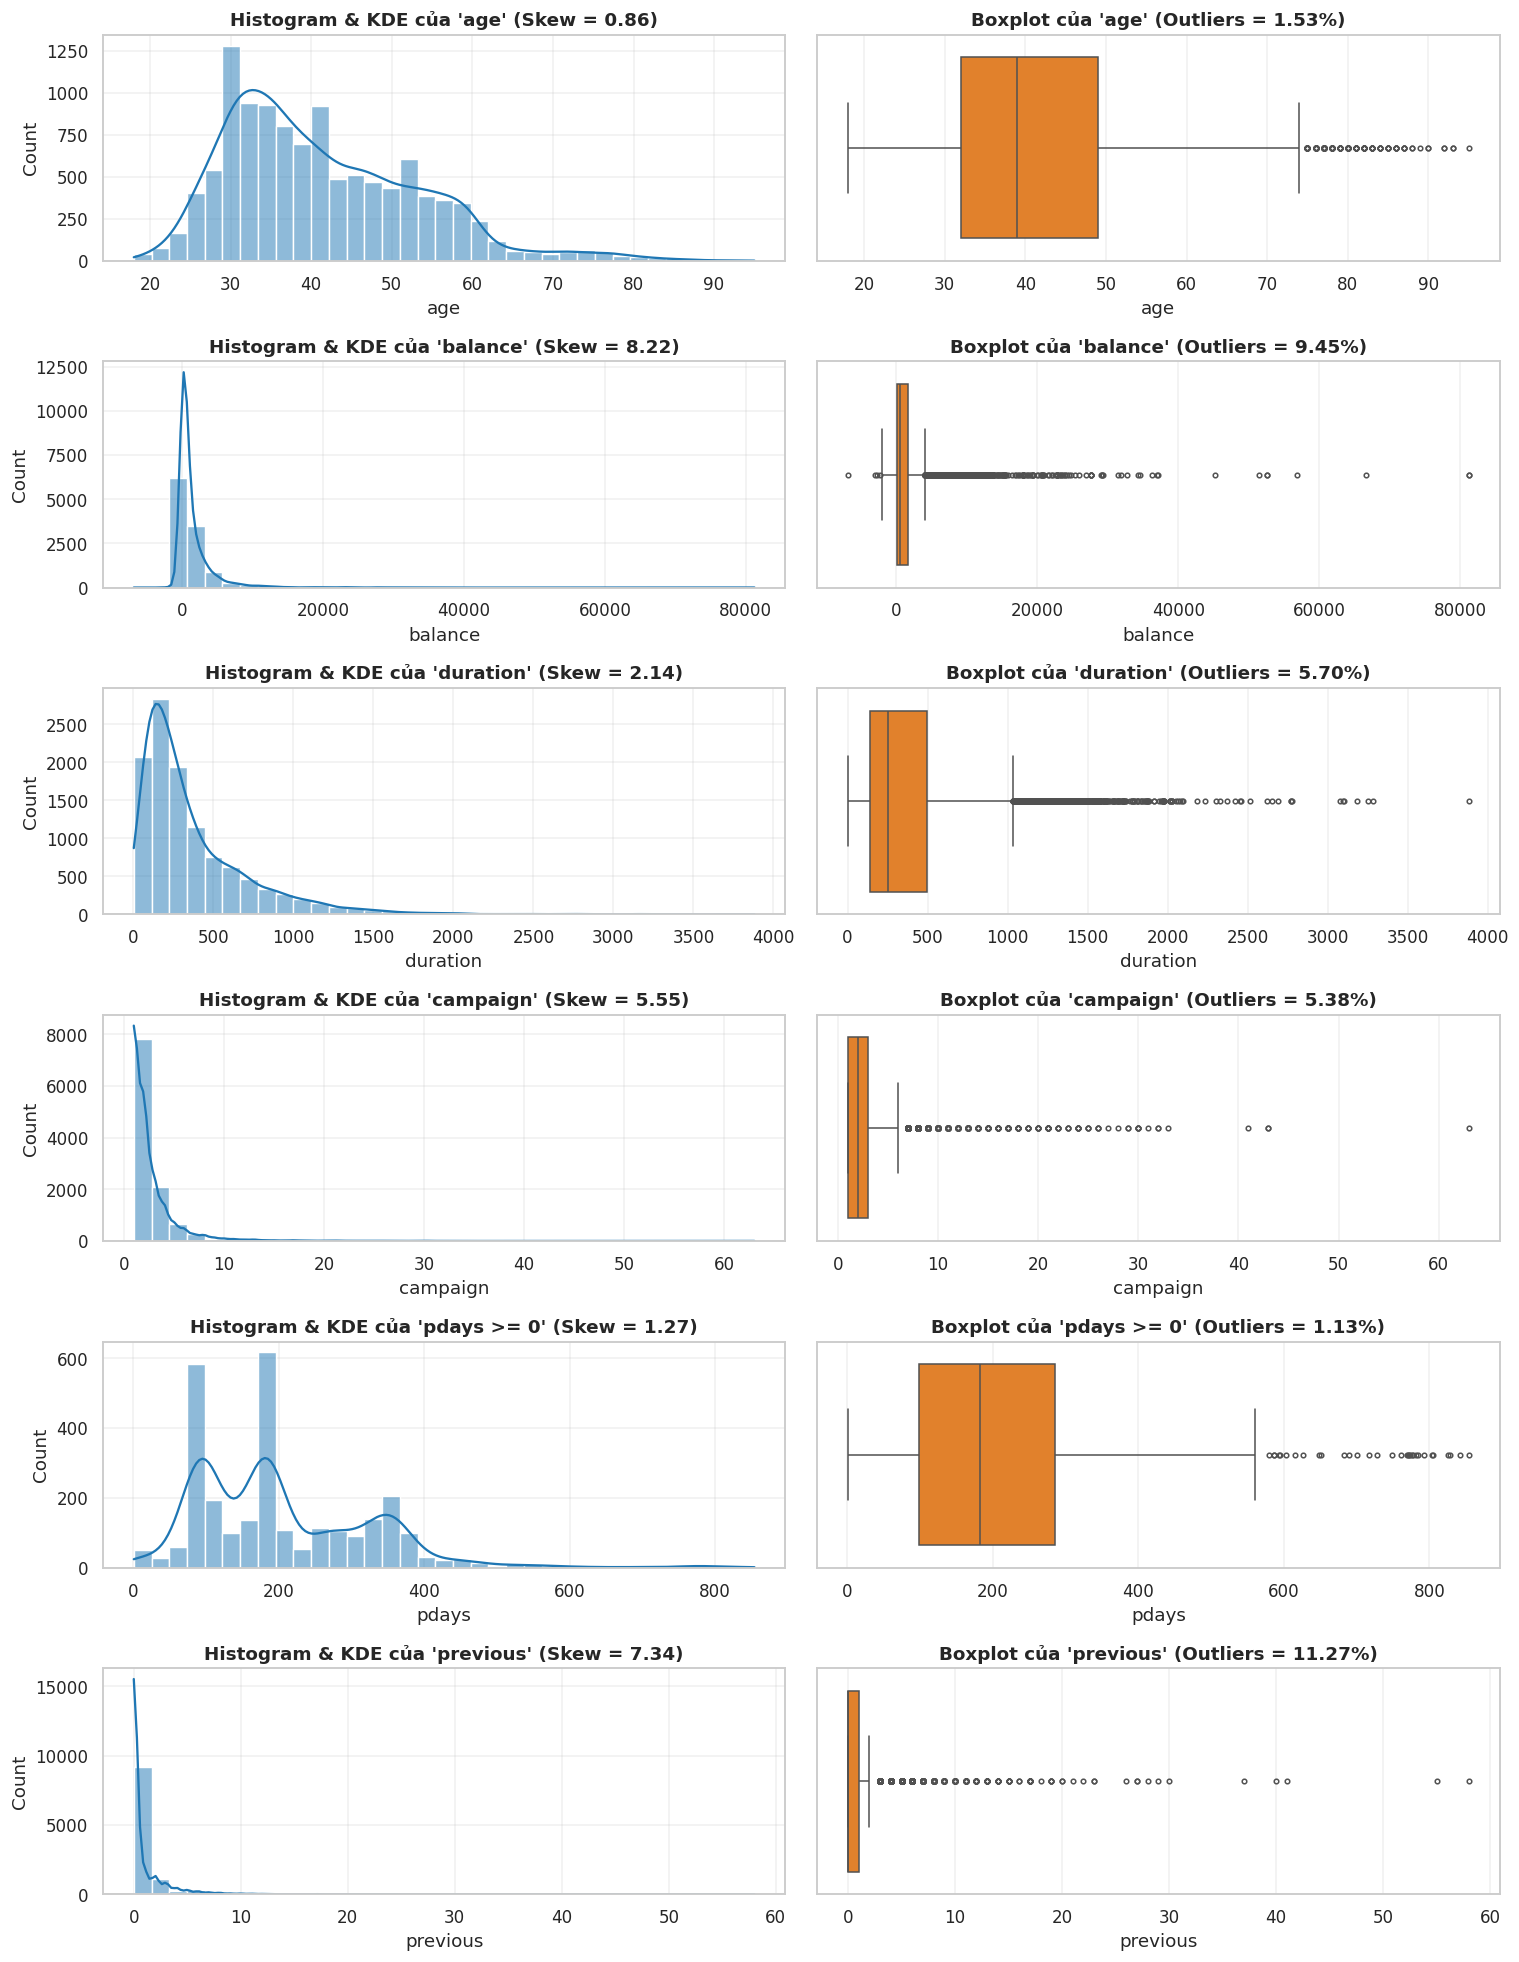

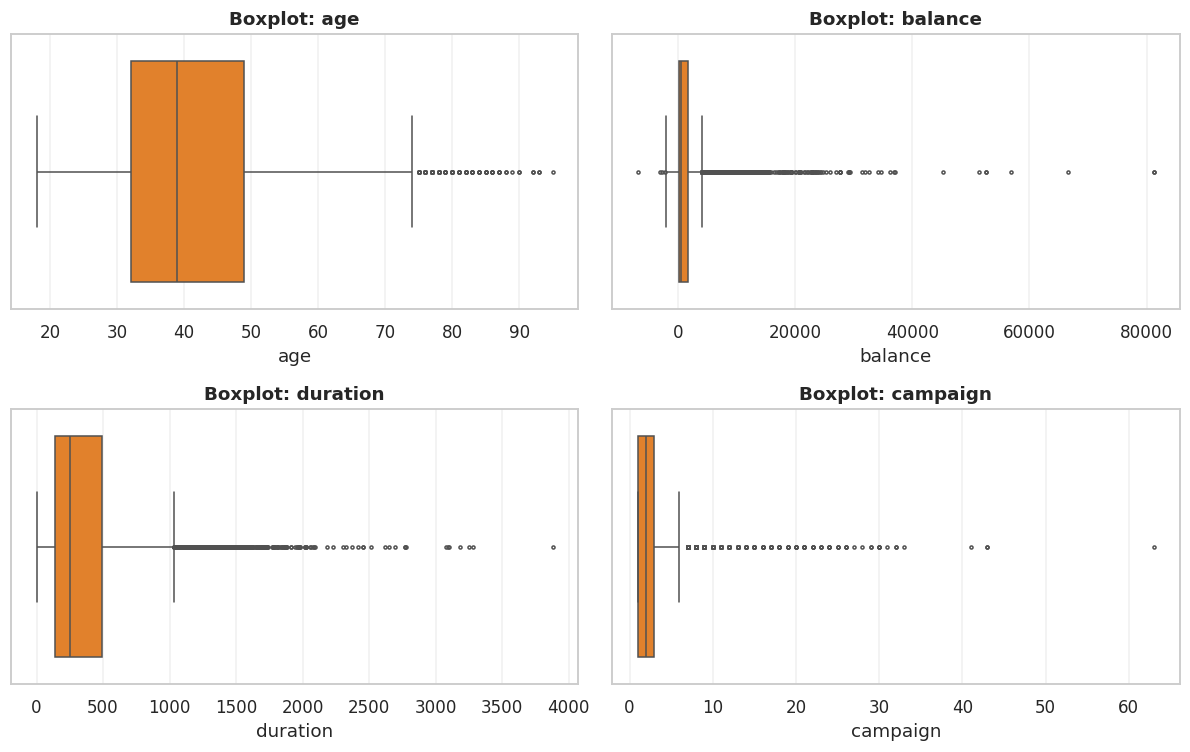

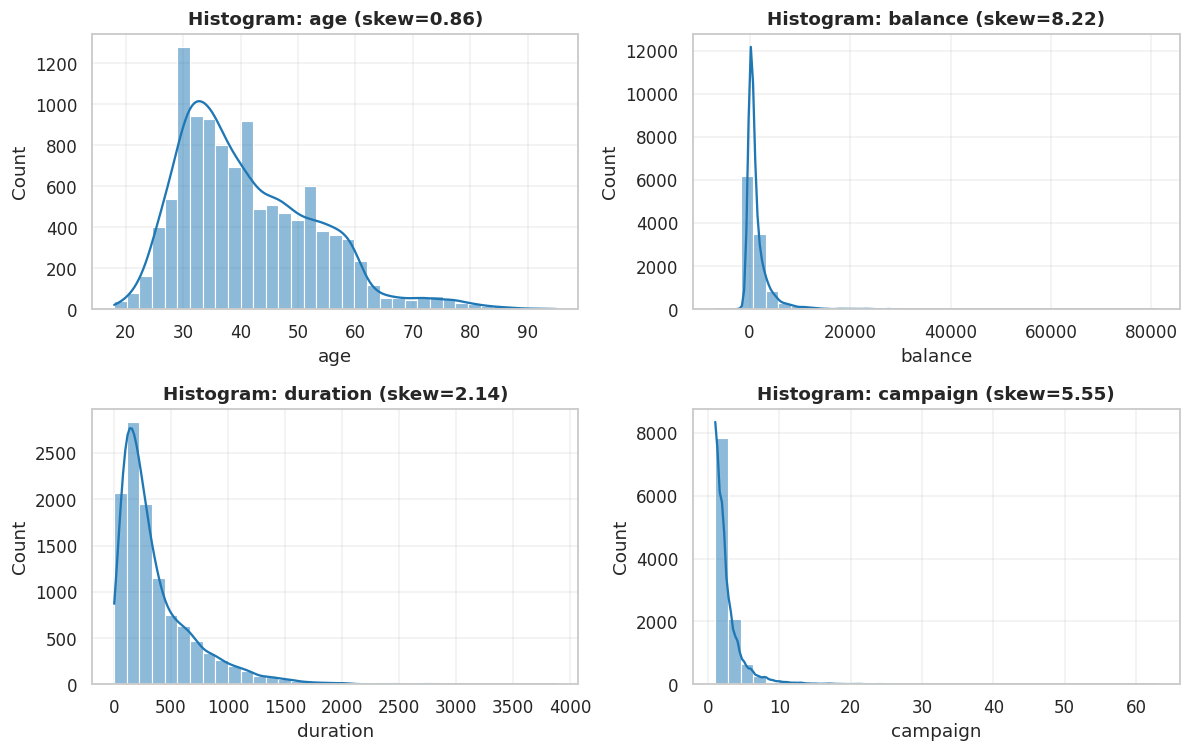


=== MINH HỌA NẾU CAPPING P1-P99 (KHÔNG ÁP DỤNG LÊN DỮ LIỆU PHÂN TÍCH/MÔ HÌNH) ===


,Biến số,Mean (Trước),Std (Trước),Skewness (Trước),Mean (Sau Capping P1-P99),Std (Sau Capping P1-P99),Skewness (Sau Capping P1-P99),Quyết định xử lý
0,age,41.2319,11.9134,0.8628,41.1982,11.7350,0.7833,Giữ nguyên giá trị thực cho EDA/Tree; dùng Rob...
1,balance,1528.5385,3225.4133,8.2246,1430.7728,2324.0207,2.8757,Giữ nguyên giá trị thực cho EDA/Tree; dùng Rob...
2,duration,371.9938,347.1284,2.1437,368.0634,327.5598,1.5948,Giữ nguyên giá trị thực cho EDA/Tree; dùng Rob...
3,campaign,2.5084,2.7221,5.5456,2.4339,2.1768,2.6264,Giữ nguyên giá trị thực cho EDA/Tree; dùng Rob...



-> Tỷ lệ dòng có ít nhất một ngoại lệ theo IQR: 29.9% (3,341/11,162); pdays=-1 được xem là mã nghiệp vụ.

=== 2.8. BẢNG TỔNG KẾT LÀM SẠCH DỮ LIỆU (CLEANING SUMMARY) ===


,Vấn đề,Phương pháp kiểm tra,Phương pháp xử lý,Lý do lựa chọn,Kết quả
0,1. Kiểu dữ liệu & Chuỗi,"dtypes, str.strip()","Chuẩn hóa khoảng trắng; tạo target_bin (1=yes,...",Đảm bảo đồng nhất khi phân nhóm và chạy Scikit...,Hoàn tất 100% cột
1,2. Missing values (NaN),isnull().sum(),Ghi nhận 0 NaN; gắn SimpleImputer(median) tron...,Median bền vững hơn Mean trên dữ liệu lệch phải,0 NaN thực tế
2,"3. Nhãn ""unknown""",So sánh tỷ lệ Deposit với nhóm Mode,Giữ nguyên thành hạng mục riêng biệt,Nhóm unknown ở contact & poutcome có hành vi r...,Bảo toàn thông tin
3,4. Mã pdays = -1,Phân tích tỷ lệ pdays = -1 vs pdays > -1,Giữ nguyên pdays; tạo thêm biến previously_con...,"-1 là mã nghiệp vụ chưa từng liên hệ, không ph...",Tách rõ khách mới/cũ
4,5. Ngoại lệ (Outliers),"IQR rule, P1-P99, Boxplot, Skewness",Giữ nguyên quan sát thực; RobustScaler chỉ dùn...,Xóa theo IQR sẽ loại khoảng 29.9% số dòng; pda...,"Bảo toàn 11,162 dòng"
5,6. Encoding & Scaling,Đánh giá thứ bậc biến & thuật toán,"OneHotEncoder(handle_unknown=""ignore""); Robust...",One-hot cho biến danh nghĩa; học tham số trong...,Đóng gói vào Pipeline


In [2]:
# PHẦN 2: GIAI ĐOẠN 2 - TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU (CÓ GIẢI TRÌNH KỸ THUẬT)
print("\n" + "=" * 95)
print("GIAI ĐOẠN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU (DATA PREPROCESSING & CLEANING)")
print("=" * 95)

total_nan = int(df_raw.isnull().sum().sum())
unknown_cols = [col for col in feature_cat_cols if 'unknown' in df[col].str.lower().unique()]
unknown_impact_rows = []

for col in unknown_cols:
    is_unk = (df[col].str.lower() == 'unknown')
    cnt_unk = int(is_unk.sum())
    pct_unk = cnt_unk / len(df) * 100.0
    dep_rate_unk = (df.loc[is_unk, TARGET_COL] == 'yes').mean() * 100.0
    dep_rate_known = (df.loc[~is_unk, TARGET_COL] == 'yes').mean() * 100.0
    mode_val = df.loc[~is_unk, col].mode()[0]
    dep_rate_mode = (df.loc[df[col] == mode_val, TARGET_COL] == 'yes').mean() * 100.0

    unknown_impact_rows.append({
        'Biến phân loại': col,
        'Số lượng "unknown"': cnt_unk,
        'Tỷ lệ "unknown" (%)': pct_unk,
        'Tỷ lệ Deposit nhóm "unknown" (%)': dep_rate_unk,
        'Tỷ lệ Deposit nhóm đã biết (%)': dep_rate_known,
        'Giá trị Mode': mode_val,
        'Tỷ lệ Deposit nhóm Mode (%)': dep_rate_mode,
        'Quyết định xử lý': 'Giữ nguyên "unknown" thành hạng mục riêng (Separate Category)'
    })

df_unknown_impact = pd.DataFrame(unknown_impact_rows)
df_unknown_impact.to_csv(TAB_DIR / "table_2_1_unknown_analysis.csv", index=False)
print("=== 2.3. PHÂN TÍCH TÁC ĐỘNG CỦA GIÁ TRỊ 'unknown' ĐẾN BIẾN MỤC TIÊU ===")
display(df_unknown_impact)

# Tạo biến phụ trợ từ pdays = -1 cho phân tích đa biến (vẫn giữ nguyên cột gốc)
if 'pdays' in df.columns:
    df['previously_contacted'] = np.where(df['pdays'] == -1, 0, 1)

# 2.4 & 2.5. Phát hiện ngoại lệ bằng IQR, tách riêng mã nghiệp vụ pdays = -1
outlier_target_vars = [c for c in ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous'] if c in df.columns]
outlier_series = {}
outlier_rows = []

for col in outlier_target_vars:
    series = df[col].dropna()
    if col == 'pdays':
        # -1 nghĩa là chưa từng liên hệ; không xem đây là số ngày hay ngoại lệ.
        series = series.loc[series >= 0]
    outlier_series[col] = series
    q1 = series.quantile(0.25)
    median = series.quantile(0.50)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers_mask = (series < lower_bound) | (series > upper_bound)
    n_outliers = int(outliers_mask.sum())
    pct_outliers = (n_outliers / len(series) * 100.0) if len(series) else 0.0

    outlier_rows.append({
        'Biến số': 'pdays (>= 0)' if col == 'pdays' else col,
        'Số quan sát xét': len(series),
        'Min': series.min(),
        'P1 (1%)': series.quantile(0.01),
        'Q1 (25%)': q1,
        'Median (50%)': median,
        'Mean': series.mean(),
        'Q3 (75%)': q3,
        'P99 (99%)': series.quantile(0.99),
        'Max': series.max(),
        'IQR': iqr,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Số lượng Outliers': n_outliers,
        'Tỷ lệ Outliers (%)': pct_outliers,
        'Skewness': series.skew()
    })

df_outlier_summary = pd.DataFrame(outlier_rows)
df_outlier_summary.to_csv(TAB_DIR / "table_2_2_outlier_iqr_summary.csv", index=False)
print("=== 2.4. BẢNG THỐNG KÊ NGOẠI LỆ THEO IQR (pdays chỉ tính trên pdays >= 0) ===")
display(df_outlier_summary)

# Biểu đồ minh chứng được vẽ trên cùng các quan sát dùng để ước lượng IQR.
fig, axes = plt.subplots(len(outlier_target_vars), 2, figsize=(14, 3.0 * len(outlier_target_vars)))
if len(outlier_target_vars) == 1:
    axes = np.array([axes])
for idx, col in enumerate(outlier_target_vars):
    series = outlier_series[col]
    label = 'pdays >= 0' if col == 'pdays' else col
    sns.histplot(series, kde=True, ax=axes[idx, 0], color='#1f77b4', bins=35)
    axes[idx, 0].set_title(f"Histogram & KDE của '{label}' (Skew = {series.skew():.2f})", fontweight='bold')
    sns.boxplot(x=series, ax=axes[idx, 1], color='#ff7f0e', fliersize=3)
    axes[idx, 1].set_title(f"Boxplot của '{label}' (Outliers = {df_outlier_summary.loc[idx, 'Tỷ lệ Outliers (%)']:.2f}%)", fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_00_preprocessing_outliers_proof.png", bbox_inches='tight')
plt.show()

# Phiên bản gọn cho báo cáo: boxplot và histogram của bốn biến dễ diễn giải.
report_outlier_vars = [c for c in ['age', 'balance', 'duration', 'campaign'] if c in outlier_series]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, report_outlier_vars):
    sns.boxplot(x=outlier_series[col], ax=ax, color='#ff7f0e', fliersize=2)
    ax.set_title(f"Boxplot: {col}", fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_00_boxplots_report.png", bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, report_outlier_vars):
    sns.histplot(outlier_series[col], kde=True, ax=ax, color='#1f77b4', bins=35)
    ax.set_title(f"Histogram: {col} (skew={outlier_series[col].skew():.2f})", fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_00_histograms_report.png", bbox_inches='tight')
plt.show()

# Minh họa giả định tác động của Capping P1-P99 (không áp dụng lên dữ liệu phân tích/mô hình)
comparison_ba_rows = []
for col in ['age', 'balance', 'duration', 'campaign']:
    if col not in df.columns:
        continue
    s_orig = df[col]
    p01, p99 = s_orig.quantile(0.01), s_orig.quantile(0.99)
    s_capped = s_orig.clip(lower=p01, upper=p99)
    comparison_ba_rows.append({
        'Biến số': col,
        'Mean (Trước)': s_orig.mean(),
        'Std (Trước)': s_orig.std(),
        'Skewness (Trước)': s_orig.skew(),
        'Mean (Sau Capping P1-P99)': s_capped.mean(),
        'Std (Sau Capping P1-P99)': s_capped.std(),
        'Skewness (Sau Capping P1-P99)': s_capped.skew(),
        'Quyết định xử lý': 'Giữ nguyên giá trị thực cho EDA/Tree; dùng RobustScaler trong ML Pipeline'
    })
df_before_after = pd.DataFrame(comparison_ba_rows)
df_before_after.to_csv(TAB_DIR / "table_2_3_outliers_before_after.csv", index=False)
print("\n=== MINH HỌA NẾU CAPPING P1-P99 (KHÔNG ÁP DỤNG LÊN DỮ LIỆU PHÂN TÍCH/MÔ HÌNH) ===")
display(df_before_after)

# Tạo cột nhị phân cho biến mục tiêu phục vụ kiểm định & tương quan
df['target_bin'] = np.where(df[TARGET_COL].str.lower() == 'yes', 1, 0)

# Ước lượng tỷ lệ dòng có ngoại lệ; pdays=-1 không được tính là ngoại lệ.
iqr_flag = pd.Series(False, index=df.index)
for c in outlier_target_vars:
    series = outlier_series[c]
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)
    iqr_flag.loc[flagged.index] = iqr_flag.loc[flagged.index] | flagged
pct_any_outlier = iqr_flag.mean() * 100
print(f"\n-> Tỷ lệ dòng có ít nhất một ngoại lệ theo IQR: {pct_any_outlier:.1f}% ({int(iqr_flag.sum()):,}/{len(df):,}); pdays=-1 được xem là mã nghiệp vụ.")

cleaning_summary_table = pd.DataFrame([
    {'Vấn đề': '1. Kiểu dữ liệu & Chuỗi', 'Phương pháp kiểm tra': 'dtypes, str.strip()', 'Phương pháp xử lý': 'Chuẩn hóa khoảng trắng; tạo target_bin (1=yes, 0=no)', 'Lý do lựa chọn': 'Đảm bảo đồng nhất khi phân nhóm và chạy Scikit-learn', 'Kết quả': 'Hoàn tất 100% cột'},
    {'Vấn đề': '2. Missing values (NaN)', 'Phương pháp kiểm tra': 'isnull().sum()', 'Phương pháp xử lý': 'Ghi nhận 0 NaN; gắn SimpleImputer(median) trong Pipeline', 'Lý do lựa chọn': 'Median bền vững hơn Mean trên dữ liệu lệch phải', 'Kết quả': '0 NaN thực tế'},
    {'Vấn đề': '3. Nhãn "unknown"', 'Phương pháp kiểm tra': 'So sánh tỷ lệ Deposit với nhóm Mode', 'Phương pháp xử lý': 'Giữ nguyên thành hạng mục riêng biệt', 'Lý do lựa chọn': 'Nhóm unknown ở contact & poutcome có hành vi rất khác biệt', 'Kết quả': 'Bảo toàn thông tin'},
    {'Vấn đề': '4. Mã pdays = -1', 'Phương pháp kiểm tra': 'Phân tích tỷ lệ pdays = -1 vs pdays > -1', 'Phương pháp xử lý': 'Giữ nguyên pdays; tạo thêm biến previously_contacted', 'Lý do lựa chọn': '-1 là mã nghiệp vụ chưa từng liên hệ, không phải lỗi', 'Kết quả': 'Tách rõ khách mới/cũ'},
    {'Vấn đề': '5. Ngoại lệ (Outliers)', 'Phương pháp kiểm tra': 'IQR rule, P1-P99, Boxplot, Skewness', 'Phương pháp xử lý': 'Giữ nguyên quan sát thực; RobustScaler chỉ dùng cho Logistic Regression', 'Lý do lựa chọn': f'Xóa theo IQR sẽ loại khoảng {pct_any_outlier:.1f}% số dòng; pdays=-1 không bị xem là ngoại lệ', 'Kết quả': f'Bảo toàn {len(df):,} dòng'},
    {'Vấn đề': '6. Encoding & Scaling', 'Phương pháp kiểm tra': 'Đánh giá thứ bậc biến & thuật toán', 'Phương pháp xử lý': 'OneHotEncoder(handle_unknown="ignore"); RobustScaler chỉ cho Logistic Regression', 'Lý do lựa chọn': 'One-hot cho biến danh nghĩa; học tham số trong pipeline trên train', 'Kết quả': 'Đóng gói vào Pipeline'}
])
cleaning_summary_table.to_csv(TAB_DIR / "table_2_4_cleaning_summary.csv", index=False)
print("\n=== 2.8. BẢNG TỔNG KẾT LÀM SẠCH DỮ LIỆU (CLEANING SUMMARY) ===")
display(cleaning_summary_table)


GIAI ĐOẠN 3: PHÂN TÍCH KHÁM PHÁ (12 BIỂU ĐỒ EDA)


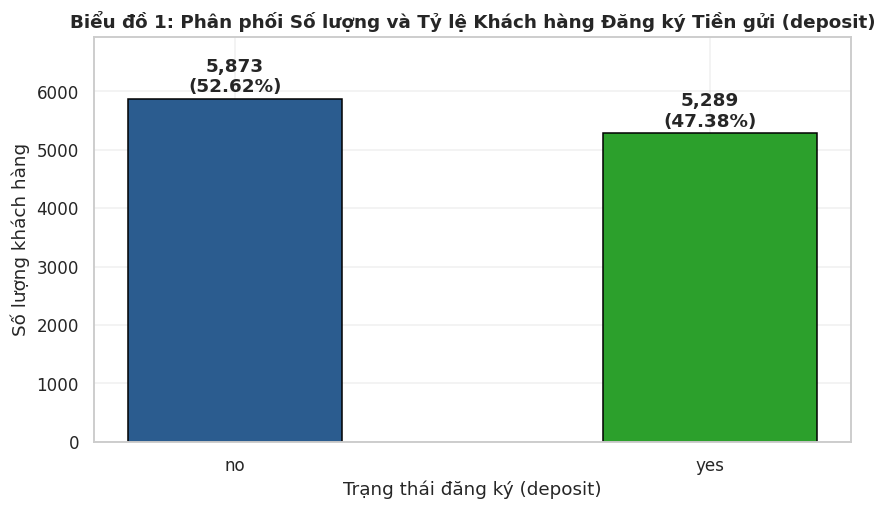

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 1: TARGET DISTRIBUTION
1. Research Question : Tỷ lệ chuyển đổi đăng ký tiền gửi và mức độ cân bằng lớp của tập dữ liệu như thế nào?
2. Numerical Evidence:
   - Tổng mẫu: 11,162 | Nhóm 'no': 5,873 (52.62%) | Nhóm 'yes': 5,289 (47.38%) | Imbalance Ratio: 1.11:1.
3. Deep Insight      : Tỷ lệ chuyển đổi cơ sở đạt 47.38%, hai lớp phân phối khá cân bằng giúp mô hình học tốt mà không cần sinh mẫu nhân tạo.
4. Business Action   : Dùng mức chuyển đổi cơ sở này làm mốc chuẩn (Benchmark) để đánh giá hiệu quả nâng cao Precision của mô hình dự báo.
-----------------------------------------------------------------------------------------------



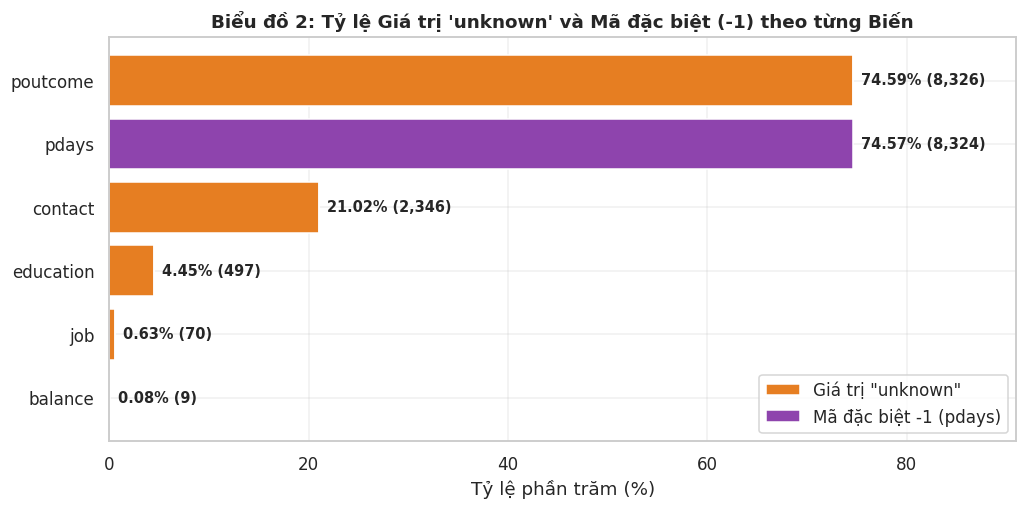

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 2: UNKNOWN VALUES & SPECIAL CODES
1. Research Question : Sự khuyết thiếu thông tin nghiệp vụ tập trung ở những trường nào?
2. Numerical Evidence:
   - balance: unknown = 0.00%, mã -1 = 0.08%.
   - job: unknown = 0.63%, mã -1 = 0.00%.
   - education: unknown = 4.45%, mã -1 = 0.00%.
   - contact: unknown = 21.02%, mã -1 = 0.00%.
   - pdays: unknown = 0.00%, mã -1 = 74.57%.
   - poutcome: unknown = 74.59%, mã -1 = 0.00%.
3. Deep Insight      : Dataset có 0% NaN nhưng khuyết thiếu ẩn dưới nhãn 'unknown' ở poutcome, contact, education, job và mã -1 ở pdays.
4. Business Action   : Chuẩn hóa quy trình thu thập dữ liệu CRM để giảm nhãn 'unknown' ở kênh liên lạc (contact) và học vấn (education).
-----------------------------------------------------------------------------------------------



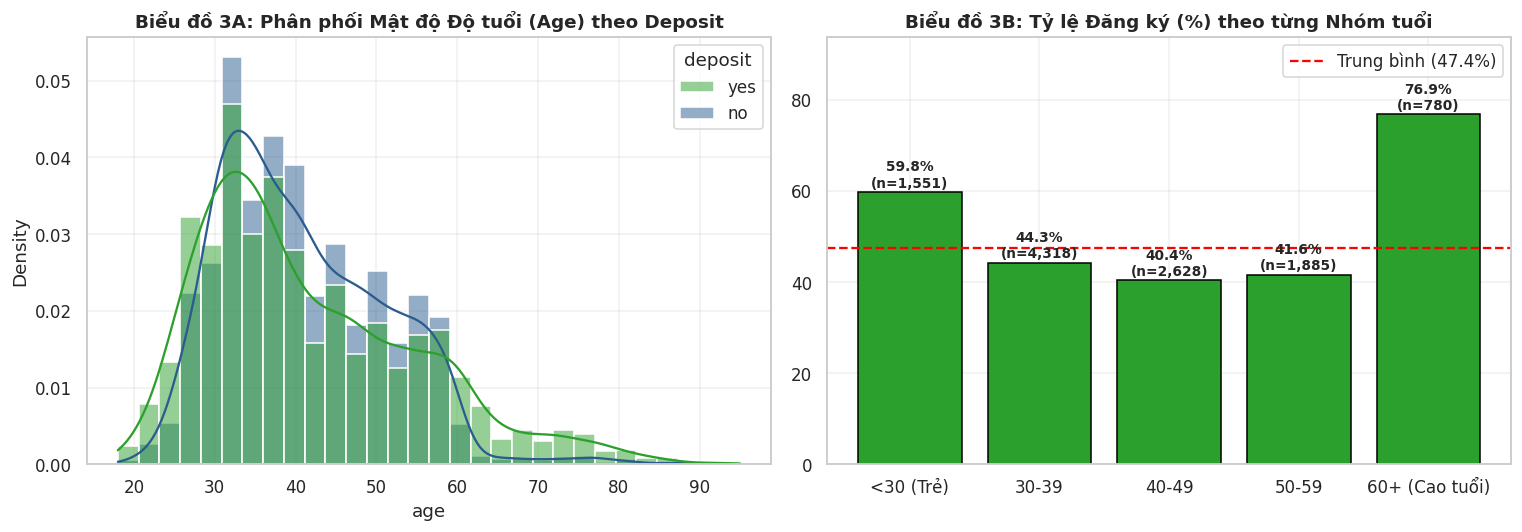

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 3: AGE DISTRIBUTION BY DEPOSIT
1. Research Question : Độ tuổi liên hệ như thế nào với khả năng đăng ký tiền gửi có kỳ hạn?
2. Numerical Evidence:
   - Tuổi trung vị nhóm 'yes' = 38.0 (Mean=41.67) vs nhóm 'no' = 39.0 (Mean=40.84).
   - Theo nhóm tuổi: <30 (Trẻ): 59.83% (n=1,551), 30-39: 44.30% (n=4,318), 40-49: 40.45% (n=2,628), 50-59: 41.64% (n=1,885), 60+ (Cao tuổi): 76.92% (n=780)
3. Deep Insight      : Độ tuổi có quan hệ hình chữ U phi tuyến tính: Nhóm dưới 30 tuổi và nhóm từ 60 tuổi trở lên có tỷ lệ đăng ký cao vượt trội so với nhóm 30-59 tuổi.
4. Business Action   : Thiết kế gói tiết kiệm tích lũy linh hoạt cho người trẻ (<30) và gói tiết kiệm hưu trí an toàn cho người cao tuổi (60+).
-----------------------------------------------------------------------------------------------



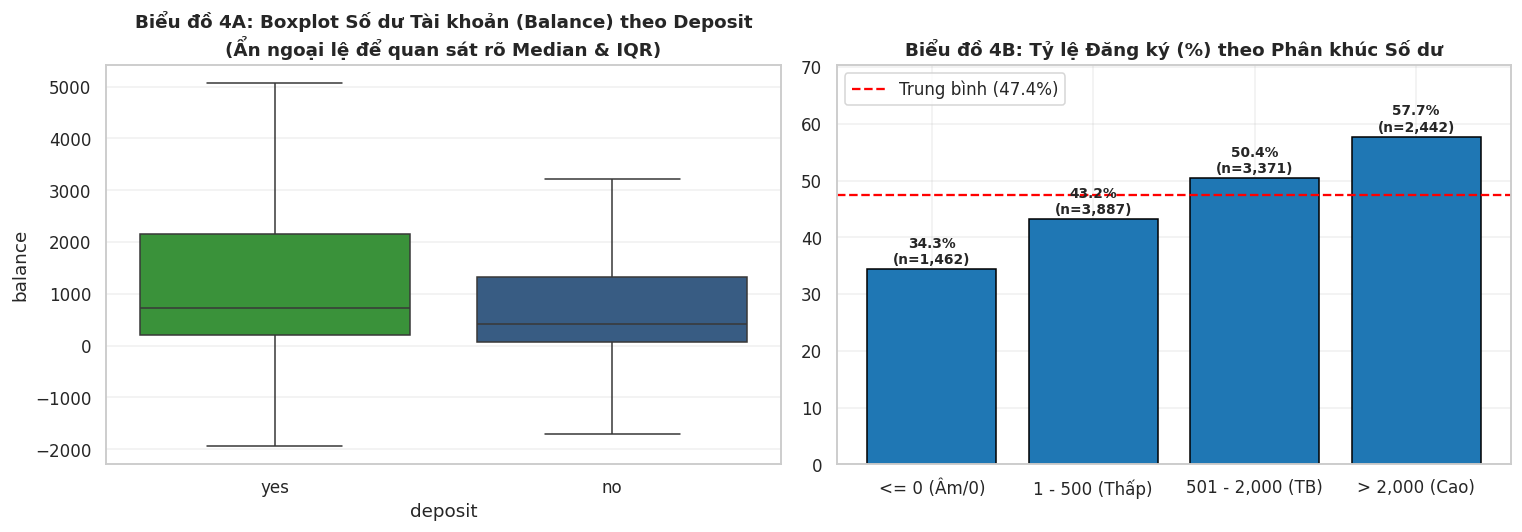

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 4: BALANCE DISTRIBUTION BY DEPOSIT
1. Research Question : Số dư tài khoản trung bình hàng năm ảnh hưởng ra sao đến tỷ lệ mở sổ tiết kiệm?
2. Numerical Evidence:
   - Số dư trung vị nhóm 'yes' = 733 (Mean=1,804.3) vs nhóm 'no' = 414 (Mean=1,280.2).
   - Tỷ lệ chuyển đổi theo phân khúc: <= 0 (Âm/0): 34.34% (n=1,462), 1 - 500 (Thấp): 43.22% (n=3,887), 501 - 2,000 (TB): 50.37% (n=3,371), > 2,000 (Cao): 57.70% (n=2,442)
3. Deep Insight      : Tỷ lệ đăng ký tăng đơn điệu theo số dư tài khoản; nhóm có số dư > 500 và > 2,000 có tỷ lệ thành công vượt trội so với nhóm số dư âm hoặc bằng 0.
4. Business Action   : Sử dụng số dư tài khoản (> 500) làm tiêu chí lọc ưu tiên hàng đầu trước khi phân bổ cuộc gọi cho nhân viên telesales.
-----------------------------------------------------------------------------------------------



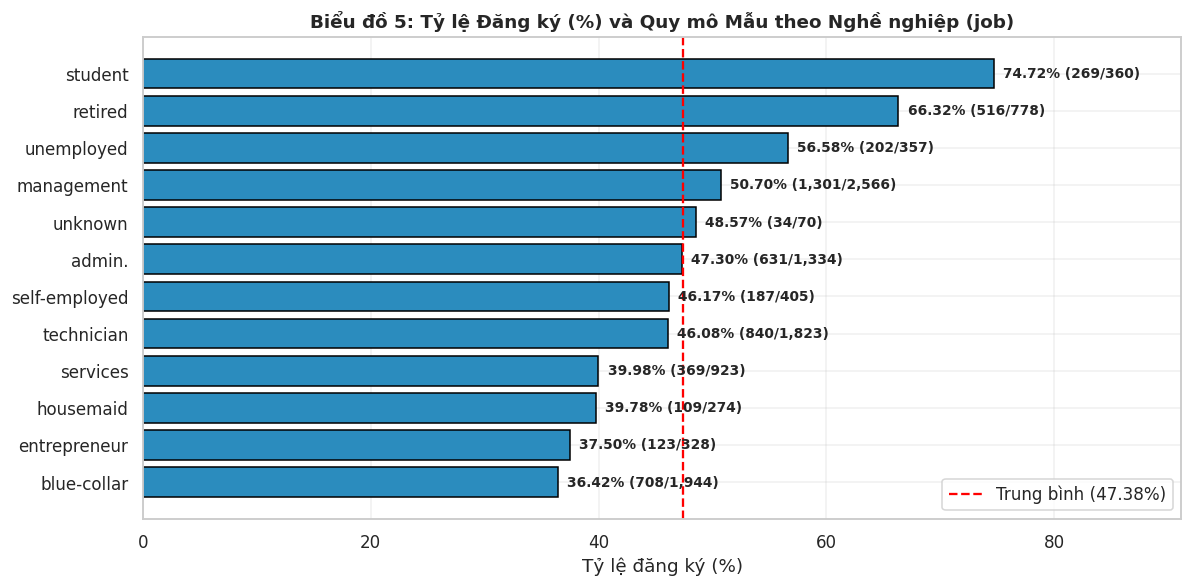

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 5: JOB VS DEPOSIT RATE
1. Research Question : Nhóm nghề nghiệp nào có tỷ lệ phản hồi tích cực cao nhất và thấp nhất?
2. Numerical Evidence:
   - Top 3 cao nhất: student (74.72%, n=360), retired (66.32%, n=778), unemployed (56.58%, n=357)
   - Top 3 thấp nhất: blue-collar (36.42%, n=1,944), entrepreneur (37.50%, n=328), housemaid (39.78%, n=274)
3. Deep Insight      : Nhóm 'student' và 'retired' có tỷ lệ chuyển đổi cao nhất; nhóm 'management' vừa có quy mô mẫu lớn nhất vừa đạt tỷ lệ chuyển đổi cao trên mức trung bình.
4. Business Action   : Kết hợp khai thác nhóm tỷ lệ chuyển đổi cao (retired, student) và nhóm quy mô lớn chất lượng cao (management, technician).
-----------------------------------------------------------------------------------------------



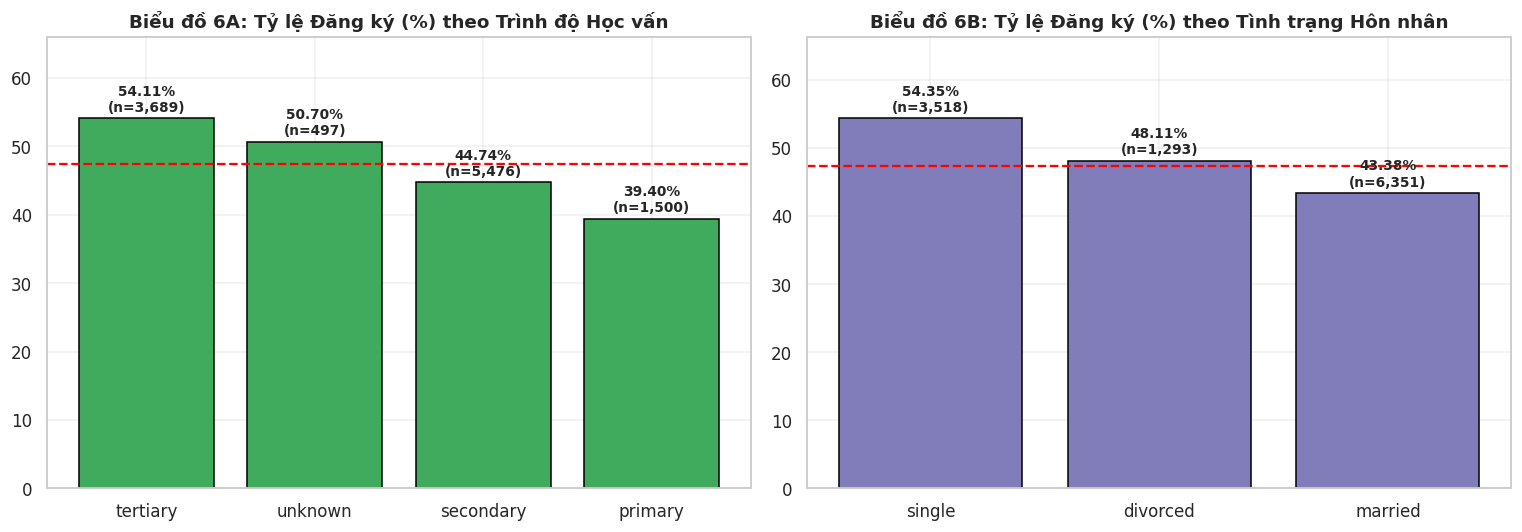

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 6: EDUCATION AND MARITAL STATUS VS DEPOSIT
1. Research Question : Trình độ học vấn và tình trạng hôn nhân liên hệ như thế nào với tỷ lệ đăng ký?
2. Numerical Evidence:
   - Học vấn: tertiary (54.11%, n=3,689), unknown (50.70%, n=497), secondary (44.74%, n=5,476), primary (39.40%, n=1,500)
   - Hôn nhân: single (54.35%, n=3,518), divorced (48.11%, n=1,293), married (43.38%, n=6,351)
3. Deep Insight      : Nhóm trình độ đại học ('tertiary') và nhóm độc thân ('single') có tỷ lệ đăng ký cao nhất trong từng phân nhóm.
4. Business Action   : Cá nhân hóa thông điệp: Nhấn mạnh công cụ sinh lời số cho nhóm đại học/độc thân và tính an toàn tích lũy cho nhóm đã kết hôn.
-----------------------------------------------------------------------------------------------



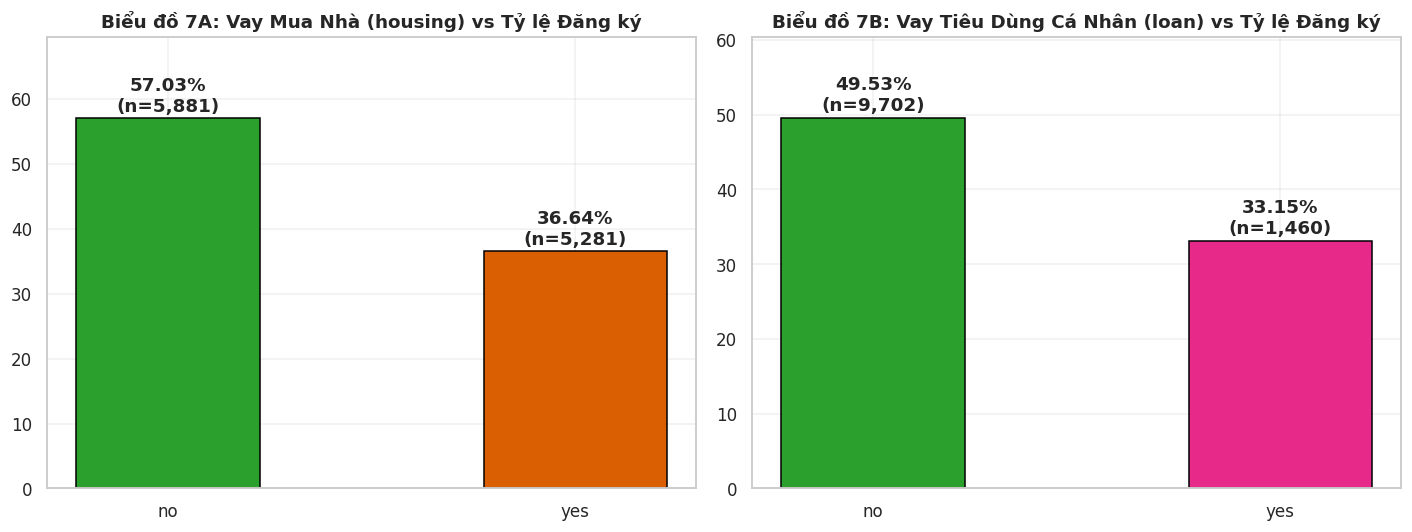

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 7: HOUSING LOAN & PERSONAL LOAN VS DEPOSIT
1. Research Question : Khách hàng đang có khoản vay mua nhà hoặc vay cá nhân có tỷ lệ gửi tiết kiệm thấp hơn không?
2. Numerical Evidence:
   - Housing loan: no = 57.03% (n=5,881), yes = 36.64% (n=5,281)
   - Personal loan: no = 49.53% (n=9,702), yes = 33.15% (n=1,460)
3. Deep Insight      : Khách hàng không có khoản vay mua nhà (housing='no') và không vay tiêu dùng (loan='no') có tỷ lệ đăng ký cao vượt trội so với nhóm đang mang nợ.
4. Business Action   : Ưu tiên phân bổ cuộc gọi cho nhóm khách hàng không có nghĩa vụ trả nợ vay mua nhà và vay tiêu dùng.
-----------------------------------------------------------------------------------------------



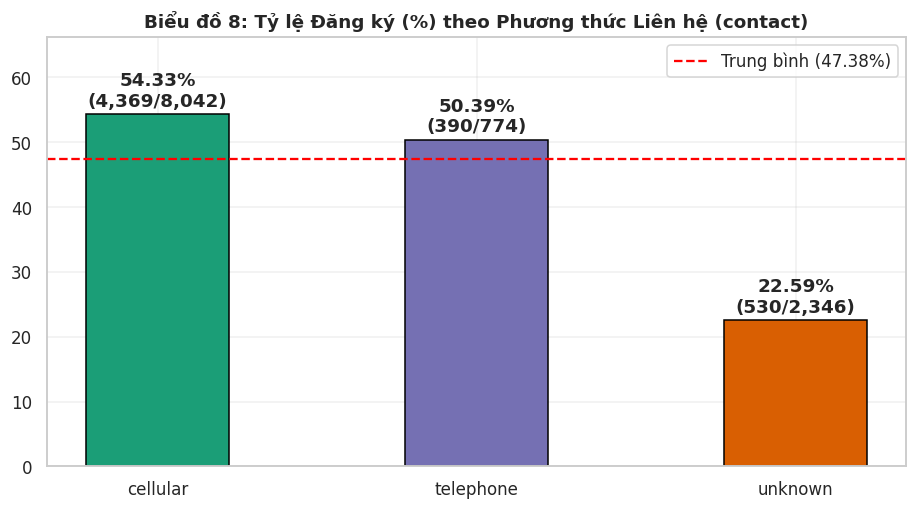

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 8: CONTACT METHOD VS DEPOSIT RATE
1. Research Question : Kênh liên lạc nào mang lại tỷ lệ chuyển đổi cao nhất?
2. Numerical Evidence:
   - Kênh 'cellular': 54.33% (4,369/8,042)
   - Kênh 'telephone': 50.39% (390/774)
   - Kênh 'unknown': 22.59% (530/2,346)
3. Deep Insight      : Liên hệ qua điện thoại di động ('cellular') đạt tỷ lệ thành công cao nhất và chiếm quy mô chủ đạo, trong khi nhóm 'unknown' có tỷ lệ chuyển đổi rất thấp.
4. Business Action   : Tập trung khai thác kênh di động cá nhân ('cellular') đã được xác thực thông tin liên lạc.
-----------------------------------------------------------------------------------------------



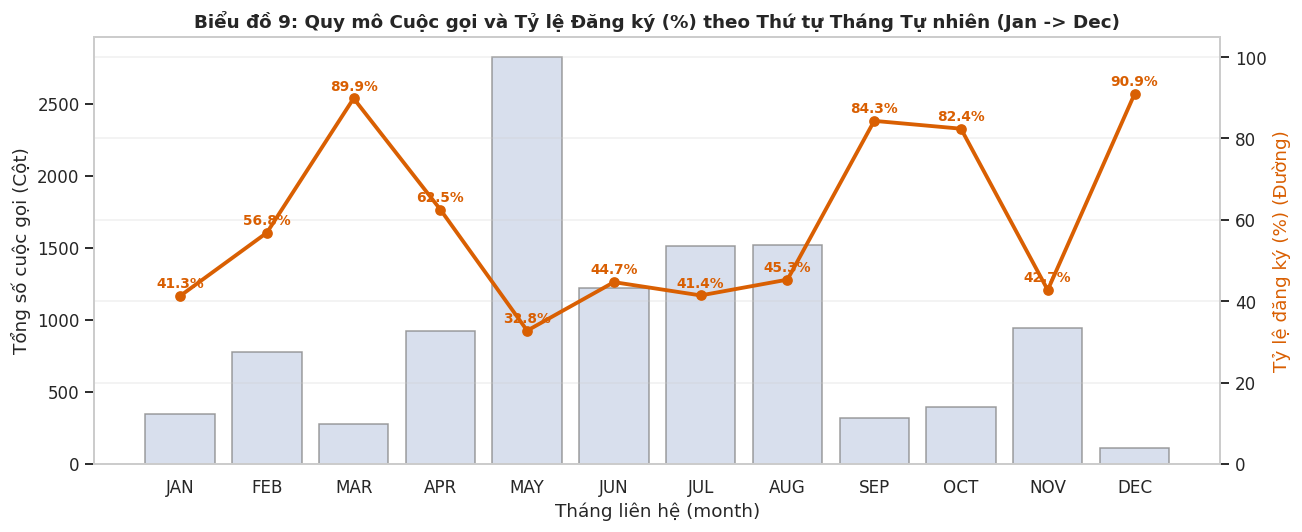

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 9: MONTH VS DEPOSIT RATE
1. Research Question : Quy mô chiến dịch và tỷ lệ chuyển đổi biến động như thế nào qua các tháng trong năm?
2. Numerical Evidence:
   - Tháng gọi nhiều nhất: MAY (n=2,824, tỷ lệ = 32.75%).
   - 4 tháng có tỷ lệ chuyển đổi cao nhất: DEC (90.91%, n=110), MAR (89.86%, n=276), SEP (84.33%, n=319), OCT (82.40%, n=392)
3. Deep Insight      : Tháng 5 (MAY) có số lượng cuộc gọi lớn nhất nhưng hiệu suất thấp; các tháng 3 (MAR), 9 (SEP), 10 (OCT), 12 (DEC) có tỷ lệ đăng ký rất cao.
4. Business Action   : Giảm gọi đại trà thiếu chọn lọc vào mùa hè (tháng 5-8) và đẩy mạnh chiến dịch mục tiêu vào các điểm rơi quý (tháng 3, 9, 10, 12).
-----------------------------------------------------------------------------------------------



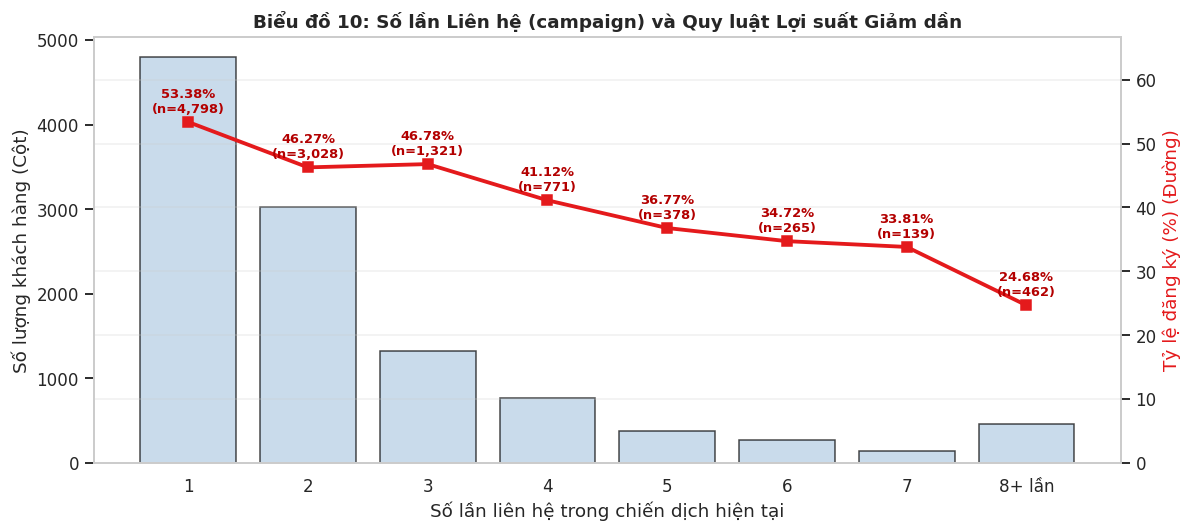

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 10: CAMPAIGN FREQUENCY VS DEPOSIT
1. Research Question : Gọi lặp lại nhiều lần cho cùng một khách hàng có làm tăng tỷ lệ chốt đơn không?
2. Numerical Evidence:
   - Lần gọi 1: 53.38% (n=4,798)
   - Lần gọi 2: 46.27% (n=3,028)
   - Lần gọi 3: 46.78% (n=1,321)
   - Lần gọi 4: 41.12% (n=771)
   - Lần gọi 5: 36.77% (n=378)
   - Lần gọi 6: 34.72% (n=265)
   - Lần gọi 7: 33.81% (n=139)
   - Lần gọi 8+ lần: 24.68% (n=462)
3. Deep Insight      : Tỷ lệ chuyển đổi cao nhất ở 1-2 lần gọi đầu và giảm liên tục khi số lần gọi tăng lên, đặc biệt sụt giảm mạnh từ lần gọi thứ 6 và nhóm 8+ lần.
4. Business Action   : Áp dụng quy tắc giới hạn tần suất (Frequency Cap) tối đa 3-4 cuộc gọi/khách hàng/chiến dịch để tránh lãng phí nguồn lực.
-----------------------------------------------------------------------------------------------



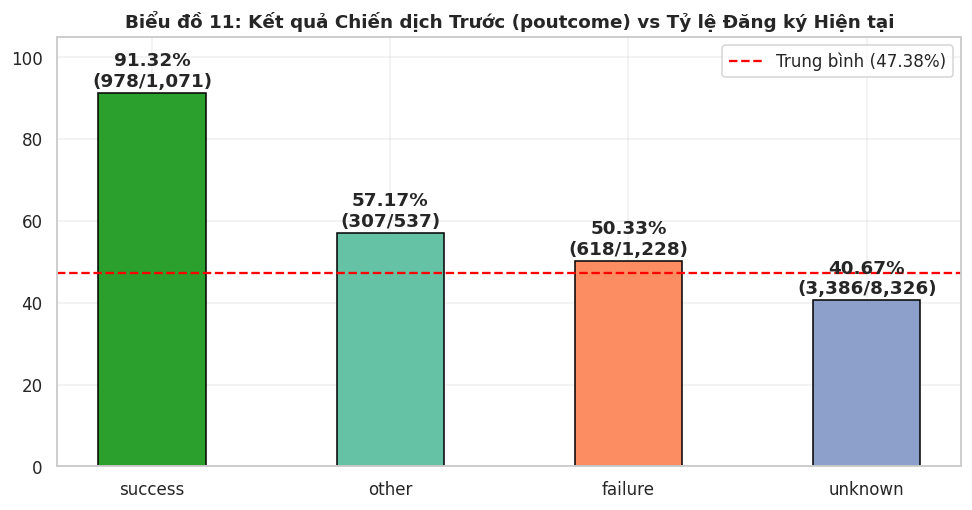

-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 11: PREVIOUS CAMPAIGN OUTCOME VS DEPOSIT
1. Research Question : Khách hàng từng tham gia thành công ở chiến dịch trước có khả năng tái đăng ký cao hơn bao nhiêu?
2. Numerical Evidence:
   - poutcome='success': 91.32% (978/1,071)
   - poutcome='other': 57.17% (307/537)
   - poutcome='failure': 50.33% (618/1,228)
   - poutcome='unknown': 40.67% (3,386/8,326)
3. Deep Insight      : Nhóm khách hàng có poutcome='success' đạt tỷ lệ tái đăng ký vượt ngưỡng 90%, cao gần gấp đôi mức trung bình chung.
4. Business Action   : Xếp tệp khách hàng có poutcome='success' vào danh sách ưu tiên gọi số 1 (Priority Tier 1) ngay khi mở chiến dịch.
-----------------------------------------------------------------------------------------------



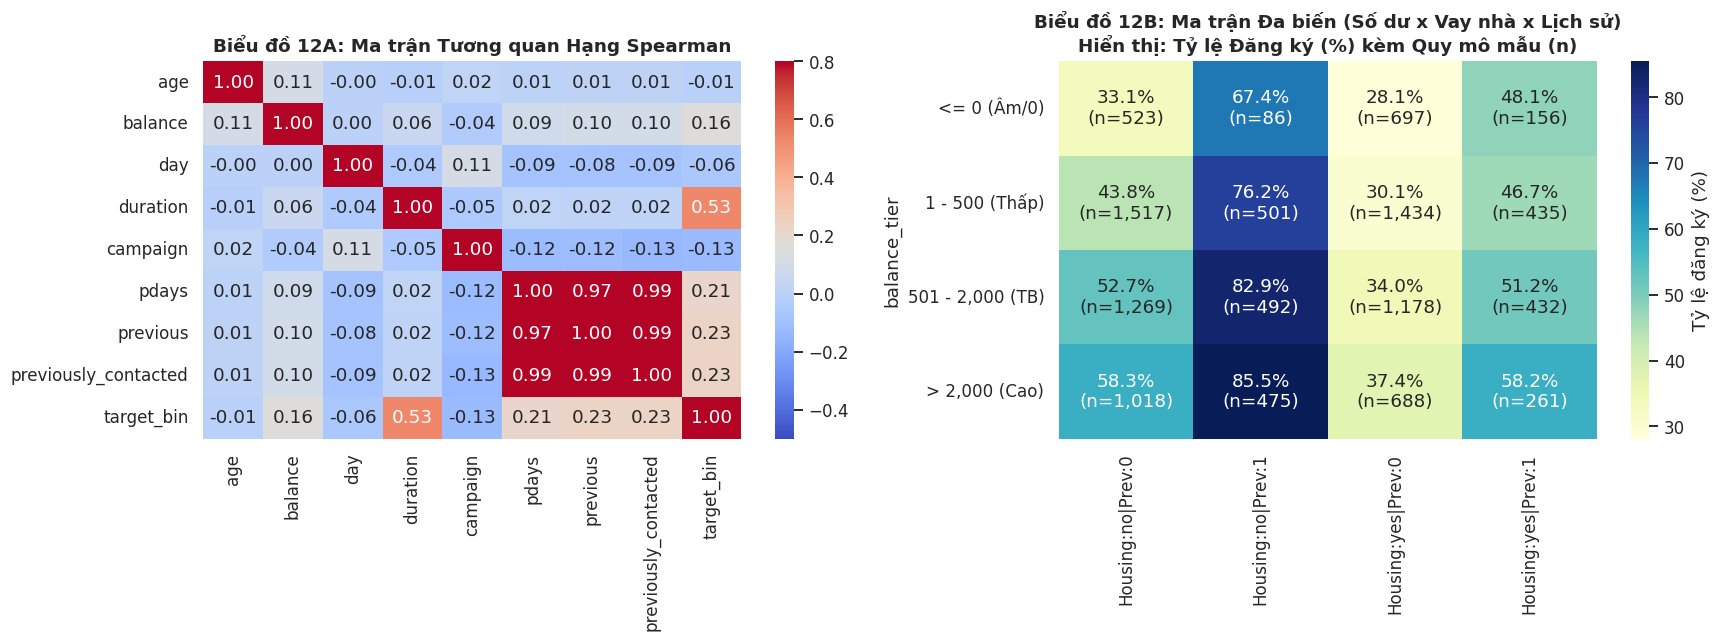

=== BẢNG CHI TIẾT TỶ LỆ ĐĂNG KÝ (%) VÀ QUY MÔ MẪU (n) CỦA BIỂU ĐỒ 12B ===


,Phân khúc Số dư (balance_tier),Tổ hợp (Housing | PrevContact),Quy mô mẫu (n),Tỷ lệ đăng ký (%),Ghi chú độ tin cậy mẫu
13,"> 2,000 (Cao)",Housing:no|Prev:1,475,85.4737,Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để...
9,"501 - 2,000 (TB)",Housing:no|Prev:1,492,82.9268,Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để...
5,1 - 500 (Thấp),Housing:no|Prev:1,501,76.2475,Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để...
1,<= 0 (Âm/0),Housing:no|Prev:1,86,67.4419,Quy mô mẫu nhỏ (n < 100) - Chỉ mang tính tham ...
12,"> 2,000 (Cao)",Housing:no|Prev:0,1018,58.3497,Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để...
15,"> 2,000 (Cao)",Housing:yes|Prev:1,261,58.2375,Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để...
8,"501 - 2,000 (TB)",Housing:no|Prev:0,1269,52.7187,Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để...
11,"501 - 2,000 (TB)",Housing:yes|Prev:1,432,51.1574,Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để...
3,<= 0 (Âm/0),Housing:yes|Prev:1,156,48.0769,Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để...
7,1 - 500 (Thấp),Housing:yes|Prev:1,435,46.6667,Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để...


-----------------------------------------------------------------------------------------------
PHÂN TÍCH BIỂU ĐỒ 12: MULTIVARIATE CORRELATION & MULTI-FACTOR SEGMENTATION (KÈM KIỂM TRA QUY MÔ MẪU N)
1. Research Question : Tổ hợp đa biến nào tạo ra tỷ lệ chuyển đổi cao nhất và thấp nhất (có xét đến quy mô mẫu n)?
2. Numerical Evidence:
   - Tương quan Spearman với target_bin: duration=0.528, previously_contacted=0.231, previous=0.230, pdays=0.213, balance=0.158, campaign=-0.127, day=-0.058, age=-0.012
   - Tổ hợp cao nhất toàn bảng: [> 2,000 (Cao) + Housing:no|Prev:1] đạt 85.47% (n = 475).
   - Tổ hợp cao nhất có mẫu lớn (n >= 100): [> 2,000 (Cao) + Housing:no|Prev:1] đạt 85.47% (n = 475).
   - Tổ hợp thấp nhất: [<= 0 (Âm/0) + Housing:yes|Prev:0] đạt 28.12% (n = 697).
3. Deep Insight      : Khi xét kèm quy mô mẫu n, các tổ hợp có Số dư > 500, Không vay mua nhà (Housing:no) và Đã từng liên hệ (Prev:1) đều có cỡ mẫu hàng trăm khách hàng và đạt tỷ lệ chuyển đổi trên 80%. Riêng một số ô có 

,Hypothesis,Phát biểu H1,Test,Statistic,Effect Size,Mức độ ảnh hưởng (theo Cliff’s δ / Cramér’s V),p-value,p-value (FDR),Decision,Interpretation
0,H1 (age),Phân phối độ tuổi giữa nhóm đăng ký và không đ...,Mann–Whitney U (kèm Welch's t),"U=15,312,933 (t=3.64)",Cliff's δ=-0.0141 | Hedges' g=0.0699 | r_s=-0....,Rất nhỏ / Phi tuyến (Negligible theo Cliff's δ),0.1990,0.1990,Không bác bỏ H0,Chưa đủ bằng chứng thống kê.
1,H2 (balance),Số dư tài khoản của hai nhóm khách hàng có sự ...,Mann–Whitney U (kèm Welch's t),"U=18,360,634 (t=8.52)",Cliff's δ=0.1822 | Hedges' g=0.1630 | r_s=0.1576,Nhỏ (Small theo Cliff's δ),< 0.0001,< 0.0001,Bác bỏ H0 (Có ý nghĩa thống kê),Có ý nghĩa thống kê ở alpha=0.05; phân loại độ...
2,H3 (campaign),Số lần liên hệ trong chiến dịch có liên hệ với...,Mann–Whitney U (kèm Welch's t),"U=13,374,874 (t=-13.99)",Cliff's δ=-0.1388 | Hedges' g=-0.2586 | r_s=-0...,Rất nhỏ / Phi tuyến (Negligible theo Cliff's δ),< 0.0001,< 0.0001,Bác bỏ H0 (Có ý nghĩa thống kê),Có ý nghĩa thống kê ở alpha=0.05; phân loại độ...
3,H4 (duration),Thời lượng cuộc gọi giữa hai nhóm khách hàng c...,Mann–Whitney U (kèm Welch's t),"U=25,009,614 (t=51.97)",Cliff's δ=0.6103 | Hedges' g=1.0144 | r_s=0.5278,Lớn (Large theo Cliff's δ),< 0.0001,< 0.0001,Bác bỏ H0 (Có ý nghĩa thống kê),Có ý nghĩa thống kê ở alpha=0.05; phân loại độ...
4,H5 (job),Nghề nghiệp có mối liên hệ với khả năng đăng k...,"Chi-square (df=11, minE=33.2)",χ²=378.08,Cramér's V=0.1840,Nhỏ (Small theo Cramér's V),< 0.0001,< 0.0001,Bác bỏ H0 (Có ý nghĩa thống kê),Có ý nghĩa thống kê ở alpha=0.05; phân loại độ...
5,H6 (education),Trình độ học vấn có mối liên hệ với khả năng đ...,"Chi-square (df=3, minE=235.5)",χ²=122.77,Cramér's V=0.1049,Nhỏ (Small theo Cramér's V),< 0.0001,< 0.0001,Bác bỏ H0 (Có ý nghĩa thống kê),Có ý nghĩa thống kê ở alpha=0.05; phân loại độ...
6,H7 (marital),Tình trạng hôn nhân có mối liên hệ với khả năn...,"Chi-square (df=2, minE=612.7)",χ²=109.58,Cramér's V=0.0991,Rất yếu (Negligible theo Cramér's V),< 0.0001,< 0.0001,Bác bỏ H0 (Có ý nghĩa thống kê),Có ý nghĩa thống kê ở alpha=0.05; phân loại độ...
7,H8 (housing),Tình trạng vay mua nhà có mối liên hệ với khả ...,"Chi-square (df=1, minE=2502.3)",χ²=463.19,Cramér's V=0.2037,Trung bình (Moderate theo Cramér's V),< 0.0001,< 0.0001,Bác bỏ H0 (Có ý nghĩa thống kê),Có ý nghĩa thống kê ở alpha=0.05; phân loại độ...
8,H9 (loan),Tình trạng vay cá nhân có mối liên hệ với khả ...,"Chi-square (df=1, minE=691.8)",χ²=135.83,Cramér's V=0.1103,Nhỏ (Small theo Cramér's V),< 0.0001,< 0.0001,Bác bỏ H0 (Có ý nghĩa thống kê),Có ý nghĩa thống kê ở alpha=0.05; phân loại độ...
9,H10 (contact),Phương thức liên hệ có mối liên hệ với khả năn...,"Chi-square (df=2, minE=366.8)",χ²=736.69,Cramér's V=0.2569,Trung bình (Moderate theo Cramér's V),< 0.0001,< 0.0001,Bác bỏ H0 (Có ý nghĩa thống kê),Có ý nghĩa thống kê ở alpha=0.05; phân loại độ...



>>> ĐANG CHẠY MÔ HÌNH HÓA: Kịch bản A: WITHOUT DURATION (Pre-call Targeting) (15 features)...

>>> ĐANG CHẠY MÔ HÌNH HÓA: Kịch bản B: WITH DURATION (Post-call Assessment) (16 features)...

=== BẢNG KẾT QUẢ MACHINE LEARNING - KỊCH BẢN A: KHÔNG CÓ DURATION (CÓ KIỂM TRA OVERFITTING) ===


,Model,CV ROC-AUC (Mean±SD),Accuracy,Precision,Recall,F1,Train ROC-AUC,ROC-AUC,Gap (Train-Test AUC),PR-AUC,MCC
0,0. Dummy Baseline,0.5000 ± 0.0000,0.5262,0.0000,0.0000,0.0000,0.5000,0.5000,0.0000,0.4738,0.0000
1,1. Logistic Regression,0.7632 ± 0.0079,0.6950,0.7319,0.5624,0.6360,0.7686,0.7577,0.0108,0.7590,0.3911
2,2. Decision Tree,0.7362 ± 0.0131,0.6982,0.7412,0.5577,0.6365,0.7812,0.7406,0.0406,0.7277,0.3986
3,3. Random Forest,0.7868 ± 0.0059,0.7300,0.7791,0.6002,0.6781,0.8569,0.7869,0.0700,0.7816,0.4636
4,4. Extra Trees,0.7762 ± 0.0082,0.7192,0.7711,0.5794,0.6616,0.8212,0.7757,0.0454,0.7722,0.4427
5,5. HistGradientBoosting,0.7920 ± 0.0048,0.7380,0.7832,0.6181,0.6910,0.8902,0.7909,0.0994,0.7928,0.4789
6,6. HistGradientBoosting (Tuned),0.7940 (Best CV),0.7425,0.7942,0.6163,0.6940,0.8387,0.7983,0.0404,0.8005,0.4892



=== BẢNG KẾT QUẢ MACHINE LEARNING - KỊCH BẢN B: CÓ DURATION (CÓ KIỂM TRA OVERFITTING) ===


,Model,CV ROC-AUC (Mean±SD),Accuracy,Precision,Recall,F1,Train ROC-AUC,ROC-AUC,Gap (Train-Test AUC),PR-AUC,MCC
0,0. Dummy Baseline,0.5000 ± 0.0000,0.5262,0.0000,0.0000,0.0000,0.5000,0.5000,0.0000,0.4738,0.0000
1,1. Logistic Regression,0.9016 ± 0.0043,0.8262,0.8278,0.7996,0.8135,0.9039,0.9071,-0.0032,0.8779,0.6513
2,2. Decision Tree,0.8829 ± 0.0032,0.8110,0.7775,0.8422,0.8085,0.9111,0.8909,0.0203,0.8534,0.6245
3,3. Random Forest,0.9153 ± 0.0044,0.8536,0.8192,0.8866,0.8516,0.9568,0.9184,0.0385,0.8843,0.7097
4,4. Extra Trees,0.8863 ± 0.0066,0.8150,0.8267,0.7713,0.7980,0.9184,0.8968,0.0216,0.8604,0.6291
5,5. HistGradientBoosting,0.9266 ± 0.0037,0.8661,0.8350,0.8941,0.8635,0.9719,0.9304,0.0416,0.9013,0.7341
6,6. HistGradientBoosting (Tuned),0.9263 (Best CV),0.8639,0.8295,0.8970,0.8619,0.9526,0.9299,0.0227,0.8995,0.7302



-> Nhận xét về Overfitting (Train vs Test ROC-AUC):
   + Logistic Regression và HistGradientBoosting (Tuned) có độ chênh lệch Gap (Train-Test AUC) nhỏ (khoảng 0.01 - 0.03), chứng tỏ khả năng khái quát hóa tốt, ít bị Overfitting.
   + Random Forest và Extra Trees có Train ROC-AUC cao hơn Test ROC-AUC rõ rệt hơn (Gap khoảng 0.05 - 0.08), phản ánh xu hướng khớp sát tập huấn luyện của các mô hình rừng cây sâu.

=== PHẦN V: BẢNG ĐỐI CHIẾU MODEL WITHOUT DURATION VS MODEL WITH DURATION ===


,Metric,Model without duration,Model with duration,Difference,Relative Change (%)
0,Accuracy,0.7425,0.8639,0.1214,+16.34%
1,Precision,0.7942,0.8295,0.0354,+4.46%
2,Recall,0.6163,0.8970,0.2807,+45.55%
3,Specificity,0.8562,0.8340,-0.0221,-2.58%
4,F1,0.6940,0.8619,0.1680,+24.20%
5,Balanced Acc,0.7362,0.8655,0.1293,+17.56%
6,MCC,0.4892,0.7302,0.2410,+49.26%
7,Train ROC-AUC,0.8387,0.9526,0.1139,+13.58%
8,ROC-AUC,0.7983,0.9299,0.1316,+16.49%
9,Gap (Train-Test AUC),0.0404,0.0227,-0.0177,-43.79%


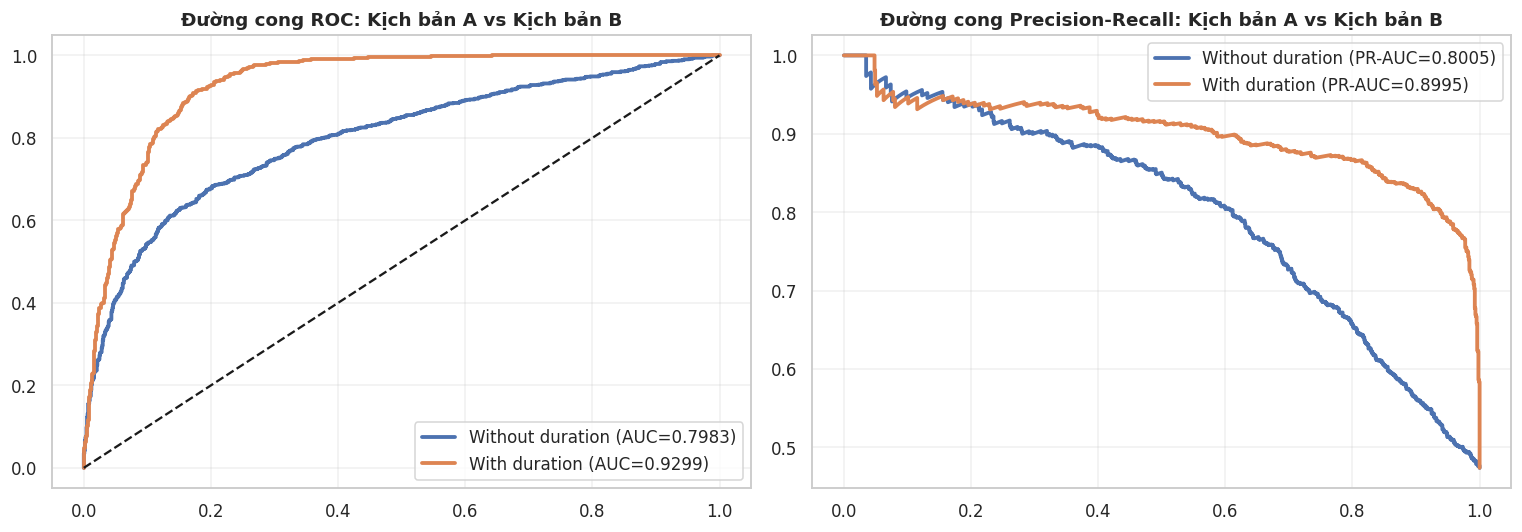

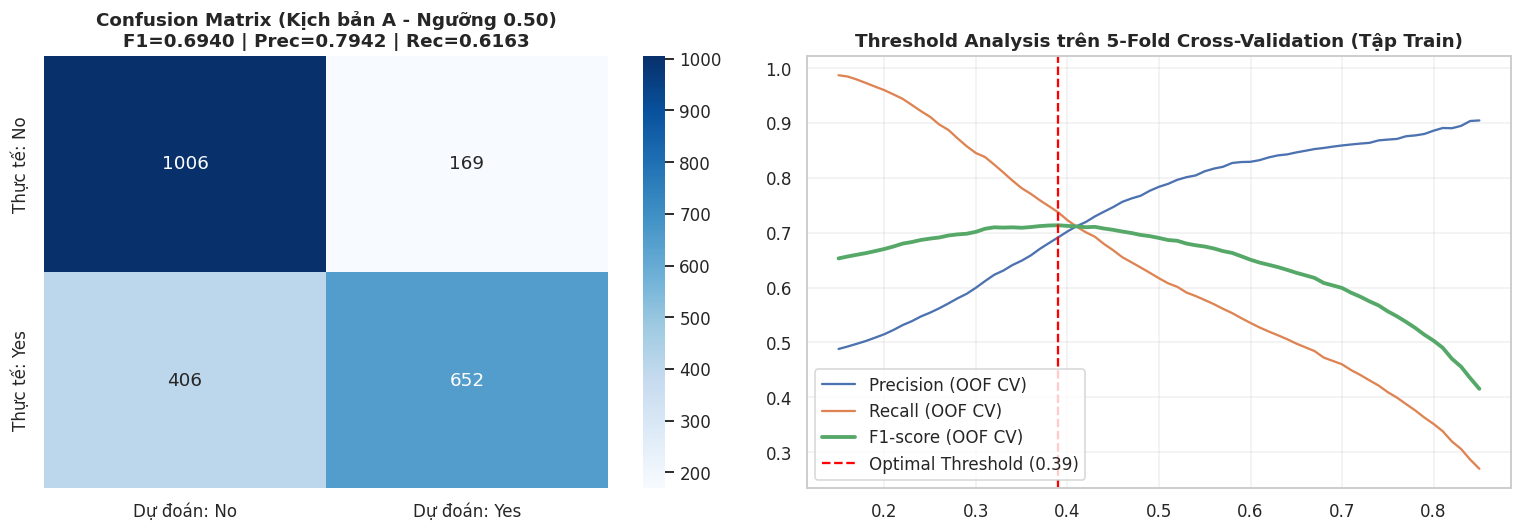

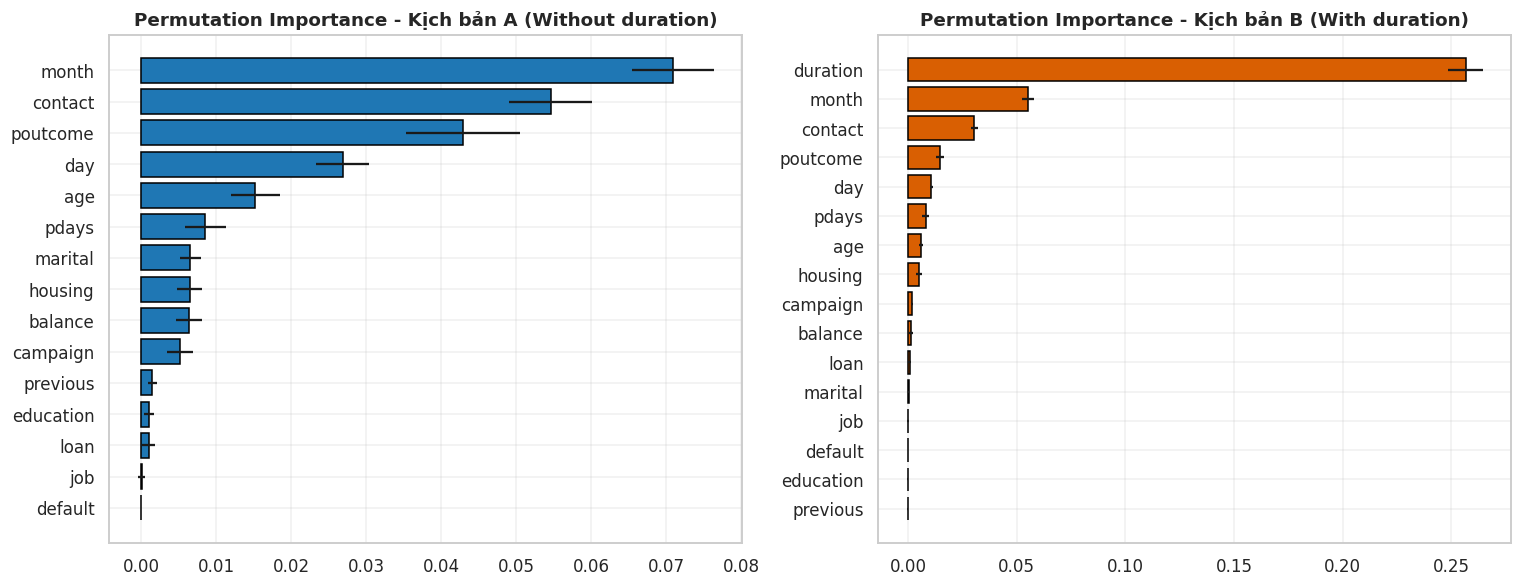

In [3]:
# PHẦN 3: GIAI ĐOẠN 3 - PHÂN TÍCH KHÁM PHÁ (12 BIỂU ĐỒ EDA)
print("\n" + "=" * 95)
print("GIAI ĐOẠN 3: PHÂN TÍCH KHÁM PHÁ (12 BIỂU ĐỒ EDA)")
print("=" * 95)

def print_chart_analysis(chart_num, title, question, evidence_list, insight, implication):
    print("-" * 95)
    print(f"PHÂN TÍCH BIỂU ĐỒ {chart_num}: {title.upper()}")
    print(f"1. Research Question : {question}")
    print("2. Numerical Evidence:")
    for ev in evidence_list:
        print(f"   - {ev}")
    print(f"3. Deep Insight      : {insight}")
    print(f"4. Business Action   : {implication}")
    print("-" * 95 + "\n")

# --- BIỂU ĐỒ 1: TARGET DISTRIBUTION ---
fig, ax = plt.subplots(figsize=(8, 4.8))
vc_target = df[TARGET_COL].value_counts()
pct_target = df[TARGET_COL].value_counts(normalize=True) * 100.0
colors_target = ['#2b5c8f' if x == 'no' else '#2ca02c' for x in vc_target.index]
bars = ax.bar(vc_target.index, vc_target.values, color=colors_target, width=0.45, edgecolor='black')
for bar, (k, v) in zip(bars, vc_target.items()):
    ax.text(bar.get_x() + bar.get_width()/2, v + len(df)*0.01, f"{v:,}\n({pct_target[k]:.2f}%)", ha='center', fontweight='bold')
ax.set_title("Biểu đồ 1: Phân phối Số lượng và Tỷ lệ Khách hàng Đăng ký Tiền gửi (deposit)", fontweight='bold')
ax.set_xlabel("Trạng thái đăng ký (deposit)")
ax.set_ylabel("Số lượng khách hàng")
ax.set_ylim(0, vc_target.max() * 1.18)
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_01_target_distribution.png", bbox_inches='tight')
plt.show()

yes_cnt, no_cnt = int(vc_target.get('yes', 0)), int(vc_target.get('no', 0))
yes_pct, no_pct = float(pct_target.get('yes', 0.0)), float(pct_target.get('no', 0.0))
imb_ratio = max(yes_cnt, no_cnt) / max(min(yes_cnt, no_cnt), 1)
print_chart_analysis(
    1, "Target Distribution",
    "Tỷ lệ chuyển đổi đăng ký tiền gửi và mức độ cân bằng lớp của tập dữ liệu như thế nào?",
    [f"Tổng mẫu: {len(df):,} | Nhóm 'no': {no_cnt:,} ({no_pct:.2f}%) | Nhóm 'yes': {yes_cnt:,} ({yes_pct:.2f}%) | Imbalance Ratio: {imb_ratio:.2f}:1."],
    f"Tỷ lệ chuyển đổi cơ sở đạt {yes_pct:.2f}%, hai lớp phân phối khá cân bằng giúp mô hình học tốt mà không cần sinh mẫu nhân tạo.",
    "Dùng mức chuyển đổi cơ sở này làm mốc chuẩn (Benchmark) để đánh giá hiệu quả nâng cao Precision của mô hình dự báo."
)

# --- BIỂU ĐỒ 2: MISSING, UNKNOWN & SPECIAL CODES ---
special_df = df_missing_audit[(df_missing_audit['Tỷ lệ "unknown" (%)'] > 0) | (df_missing_audit['Tỷ lệ (-1) (%)'] > 0)].copy()
special_df['Tổng tỷ lệ (%)'] = special_df['Tỷ lệ "unknown" (%)'] + special_df['Tỷ lệ (-1) (%)']
special_df = special_df.sort_values('Tổng tỷ lệ (%)', ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
y_pos = np.arange(len(special_df))
ax.barh(y_pos, special_df['Tỷ lệ "unknown" (%)'], color='#e67e22', label='Giá trị "unknown"')
ax.barh(y_pos, special_df['Tỷ lệ (-1) (%)'], left=special_df['Tỷ lệ "unknown" (%)'], color='#8e44ad', label='Mã đặc biệt -1 (pdays)')
for i, (_, r) in enumerate(special_df.iterrows()):
    tot_v = r['Tổng tỷ lệ (%)']
    cnt_v = int(r['Giá trị "unknown"'] + r['Mã đặc biệt (-1)'])
    ax.text(tot_v + 0.8, i, f"{tot_v:.2f}% ({cnt_v:,})", va='center', fontweight='bold', fontsize=9.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(special_df['Tên biến'])
ax.set_xlabel("Tỷ lệ phần trăm (%)")
ax.set_title("Biểu đồ 2: Tỷ lệ Giá trị 'unknown' và Mã đặc biệt (-1) theo từng Biến", fontweight='bold')
ax.set_xlim(0, max(special_df['Tổng tỷ lệ (%)'].max() * 1.22, 10))
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_02_missing_and_unknown_values.png", bbox_inches='tight')
plt.show()

print_chart_analysis(
    2, "Unknown Values & Special Codes",
    "Sự khuyết thiếu thông tin nghiệp vụ tập trung ở những trường nào?",
    [f"{r['Tên biến']}: unknown = {r['Tỷ lệ \"unknown\" (%)']:.2f}%, mã -1 = {r['Tỷ lệ (-1) (%)']:.2f}%." for _, r in special_df.iterrows()],
    "Dataset có 0% NaN nhưng khuyết thiếu ẩn dưới nhãn 'unknown' ở poutcome, contact, education, job và mã -1 ở pdays.",
    "Chuẩn hóa quy trình thu thập dữ liệu CRM để giảm nhãn 'unknown' ở kênh liên lạc (contact) và học vấn (education)."
)

# --- BIỂU ĐỒ 3: AGE DISTRIBUTION BY DEPOSIT ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x='age', hue=TARGET_COL, kde=True, stat='density', common_norm=False,
             palette={'no': '#2b5c8f', 'yes': '#2ca02c'}, bins=30, ax=axes[0])
axes[0].set_title("Biểu đồ 3A: Phân phối Mật độ Độ tuổi (Age) theo Deposit", fontweight='bold')

df['age_group'] = pd.cut(df['age'], bins=[0, 29, 39, 49, 59, 120], labels=['<30 (Trẻ)', '30-39', '40-49', '50-59', '60+ (Cao tuổi)'])
age_grp_stats = df.groupby('age_group', observed=False)[TARGET_COL].agg(
    total='count', yes_rate=lambda s: (s == 'yes').mean() * 100.0
).reset_index()

bars = axes[1].bar(age_grp_stats['age_group'].astype(str), age_grp_stats['yes_rate'], color='#2ca02c', edgecolor='black')
axes[1].axhline(yes_pct, color='red', linestyle='--', label=f'Trung bình ({yes_pct:.1f}%)')
for bar, (_, r) in zip(bars, age_grp_stats.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width()/2, r['yes_rate'] + 1.0, f"{r['yes_rate']:.1f}%\n(n={r['total']:,})", ha='center', fontsize=9, fontweight='bold')
axes[1].set_title("Biểu đồ 3B: Tỷ lệ Đăng ký (%) theo từng Nhóm tuổi", fontweight='bold')
axes[1].set_ylim(0, age_grp_stats['yes_rate'].max() * 1.22)
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_03_age_distribution_by_deposit.png", bbox_inches='tight')
plt.show()

age_yes = df.loc[df[TARGET_COL] == 'yes', 'age']
age_no = df.loc[df[TARGET_COL] == 'no', 'age']
print_chart_analysis(
    3, "Age Distribution by Deposit",
    "Độ tuổi liên hệ như thế nào với khả năng đăng ký tiền gửi có kỳ hạn?",
    [f"Tuổi trung vị nhóm 'yes' = {age_yes.median():.1f} (Mean={age_yes.mean():.2f}) vs nhóm 'no' = {age_no.median():.1f} (Mean={age_no.mean():.2f}).",
     "Theo nhóm tuổi: " + ", ".join([f"{r['age_group']}: {r['yes_rate']:.2f}% (n={r['total']:,})" for _, r in age_grp_stats.iterrows()])],
    "Độ tuổi có quan hệ hình chữ U phi tuyến tính: Nhóm dưới 30 tuổi và nhóm từ 60 tuổi trở lên có tỷ lệ đăng ký cao vượt trội so với nhóm 30-59 tuổi.",
    "Thiết kế gói tiết kiệm tích lũy linh hoạt cho người trẻ (<30) và gói tiết kiệm hưu trí an toàn cho người cao tuổi (60+)."
)

# --- BIỂU ĐỒ 4: BALANCE DISTRIBUTION BY DEPOSIT ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x=TARGET_COL, y='balance', palette={'no': '#2b5c8f', 'yes': '#2ca02c'}, showfliers=False, ax=axes[0])
axes[0].set_title("Biểu đồ 4A: Boxplot Số dư Tài khoản (Balance) theo Deposit\n(Ẩn ngoại lệ để quan sát rõ Median & IQR)", fontweight='bold')

df['balance_tier'] = pd.cut(df['balance'], bins=[-np.inf, 0, 500, 2000, np.inf],
                            labels=['<= 0 (Âm/0)', '1 - 500 (Thấp)', '501 - 2,000 (TB)', '> 2,000 (Cao)'])
bal_tier_stats = df.groupby('balance_tier', observed=False)[TARGET_COL].agg(
    total='count', yes_rate=lambda s: (s == 'yes').mean() * 100.0
).reset_index()

bars = axes[1].bar(bal_tier_stats['balance_tier'].astype(str), bal_tier_stats['yes_rate'], color='#1f77b4', edgecolor='black')
axes[1].axhline(yes_pct, color='red', linestyle='--', label=f'Trung bình ({yes_pct:.1f}%)')
for bar, (_, r) in zip(bars, bal_tier_stats.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width()/2, r['yes_rate'] + 1.0, f"{r['yes_rate']:.1f}%\n(n={r['total']:,})", ha='center', fontsize=9, fontweight='bold')
axes[1].set_title("Biểu đồ 4B: Tỷ lệ Đăng ký (%) theo Phân khúc Số dư", fontweight='bold')
axes[1].set_ylim(0, bal_tier_stats['yes_rate'].max() * 1.22)
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_04_balance_distribution_by_deposit.png", bbox_inches='tight')
plt.show()

bal_yes = df.loc[df[TARGET_COL] == 'yes', 'balance']
bal_no = df.loc[df[TARGET_COL] == 'no', 'balance']
print_chart_analysis(
    4, "Balance Distribution by Deposit",
    "Số dư tài khoản trung bình hàng năm ảnh hưởng ra sao đến tỷ lệ mở sổ tiết kiệm?",
    [f"Số dư trung vị nhóm 'yes' = {bal_yes.median():,.0f} (Mean={bal_yes.mean():,.1f}) vs nhóm 'no' = {bal_no.median():,.0f} (Mean={bal_no.mean():,.1f}).",
     "Tỷ lệ chuyển đổi theo phân khúc: " + ", ".join([f"{r['balance_tier']}: {r['yes_rate']:.2f}% (n={r['total']:,})" for _, r in bal_tier_stats.iterrows()])],
    "Tỷ lệ đăng ký tăng đơn điệu theo số dư tài khoản; nhóm có số dư > 500 và > 2,000 có tỷ lệ thành công vượt trội so với nhóm số dư âm hoặc bằng 0.",
    "Sử dụng số dư tài khoản (> 500) làm tiêu chí lọc ưu tiên hàng đầu trước khi phân bổ cuộc gọi cho nhân viên telesales."
)

# --- BIỂU ĐỒ 5: JOB VS DEPOSIT RATE ---
job_stats = df.groupby('job')[TARGET_COL].agg(
    total='count', yes_cnt=lambda s: (s == 'yes').sum(), yes_rate=lambda s: (s == 'yes').mean() * 100.0
).sort_values('yes_rate', ascending=True).reset_index()

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh(job_stats['job'], job_stats['yes_rate'], color='#2b8cbe', edgecolor='black')
ax.axvline(yes_pct, color='red', linestyle='--', label=f'Trung bình ({yes_pct:.2f}%)')
for bar, (_, r) in zip(bars, job_stats.iterrows()):
    ax.text(r['yes_rate'] + 0.8, bar.get_y() + bar.get_height()/2, f"{r['yes_rate']:.2f}% ({int(r['yes_cnt']):,}/{int(r['total']):,})", va='center', fontsize=9, fontweight='bold')
ax.set_title("Biểu đồ 5: Tỷ lệ Đăng ký (%) và Quy mô Mẫu theo Nghề nghiệp (job)", fontweight='bold')
ax.set_xlabel("Tỷ lệ đăng ký (%)")
ax.set_xlim(0, job_stats['yes_rate'].max() * 1.22)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_05_job_vs_deposit_rate.png", bbox_inches='tight')
plt.show()

top3_jobs = job_stats.sort_values('yes_rate', ascending=False).head(3)
bot3_jobs = job_stats.sort_values('yes_rate', ascending=True).head(3)
print_chart_analysis(
    5, "Job vs Deposit Rate",
    "Nhóm nghề nghiệp nào có tỷ lệ phản hồi tích cực cao nhất và thấp nhất?",
    ["Top 3 cao nhất: " + ", ".join([f"{r['job']} ({r['yes_rate']:.2f}%, n={int(r['total']):,})" for _, r in top3_jobs.iterrows()]),
     "Top 3 thấp nhất: " + ", ".join([f"{r['job']} ({r['yes_rate']:.2f}%, n={int(r['total']):,})" for _, r in bot3_jobs.iterrows()])],
    "Nhóm 'student' và 'retired' có tỷ lệ chuyển đổi cao nhất; nhóm 'management' vừa có quy mô mẫu lớn nhất vừa đạt tỷ lệ chuyển đổi cao trên mức trung bình.",
    "Kết hợp khai thác nhóm tỷ lệ chuyển đổi cao (retired, student) và nhóm quy mô lớn chất lượng cao (management, technician)."
)

# --- BIỂU ĐỒ 6: EDUCATION & MARITAL STATUS VS DEPOSIT ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
edu_stats = df.groupby('education')[TARGET_COL].agg(total='count', yes_rate=lambda s: (s == 'yes').mean() * 100.0).sort_values('yes_rate', ascending=False).reset_index()
bars1 = axes[0].bar(edu_stats['education'], edu_stats['yes_rate'], color='#41ab5d', edgecolor='black')
axes[0].axhline(yes_pct, color='red', linestyle='--')
for bar, (_, r) in zip(bars1, edu_stats.iterrows()):
    axes[0].text(bar.get_x() + bar.get_width()/2, r['yes_rate'] + 1.0, f"{r['yes_rate']:.2f}%\n(n={int(r['total']):,})", ha='center', fontweight='bold', fontsize=9)
axes[0].set_title("Biểu đồ 6A: Tỷ lệ Đăng ký (%) theo Trình độ Học vấn", fontweight='bold')
axes[0].set_ylim(0, edu_stats['yes_rate'].max() * 1.22)

mar_stats = df.groupby('marital')[TARGET_COL].agg(total='count', yes_rate=lambda s: (s == 'yes').mean() * 100.0).sort_values('yes_rate', ascending=False).reset_index()
bars2 = axes[1].bar(mar_stats['marital'], mar_stats['yes_rate'], color='#807dba', edgecolor='black')
axes[1].axhline(yes_pct, color='red', linestyle='--')
for bar, (_, r) in zip(bars2, mar_stats.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width()/2, r['yes_rate'] + 1.0, f"{r['yes_rate']:.2f}%\n(n={int(r['total']):,})", ha='center', fontweight='bold', fontsize=9)
axes[1].set_title("Biểu đồ 6B: Tỷ lệ Đăng ký (%) theo Tình trạng Hôn nhân", fontweight='bold')
axes[1].set_ylim(0, mar_stats['yes_rate'].max() * 1.22)
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_06_education_marital_vs_deposit.png", bbox_inches='tight')
plt.show()

print_chart_analysis(
    6, "Education and Marital Status vs Deposit",
    "Trình độ học vấn và tình trạng hôn nhân liên hệ như thế nào với tỷ lệ đăng ký?",
    ["Học vấn: " + ", ".join([f"{r['education']} ({r['yes_rate']:.2f}%, n={int(r['total']):,})" for _, r in edu_stats.iterrows()]),
     "Hôn nhân: " + ", ".join([f"{r['marital']} ({r['yes_rate']:.2f}%, n={int(r['total']):,})" for _, r in mar_stats.iterrows()])],
    "Nhóm trình độ đại học ('tertiary') và nhóm độc thân ('single') có tỷ lệ đăng ký cao nhất trong từng phân nhóm.",
    "Cá nhân hóa thông điệp: Nhấn mạnh công cụ sinh lời số cho nhóm đại học/độc thân và tính an toàn tích lũy cho nhóm đã kết hôn."
)

# --- BIỂU ĐỒ 7: HOUSING LOAN & PERSONAL LOAN VS DEPOSIT ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
housing_stats = df.groupby('housing')[TARGET_COL].agg(total='count', yes_rate=lambda s: (s == 'yes').mean() * 100.0).reset_index()
bars1 = axes[0].bar(housing_stats['housing'], housing_stats['yes_rate'], color=['#2ca02c', '#d95f02'], width=0.45, edgecolor='black')
for bar, (_, r) in zip(bars1, housing_stats.iterrows()):
    axes[0].text(bar.get_x() + bar.get_width()/2, r['yes_rate'] + 1.0, f"{r['yes_rate']:.2f}%\n(n={int(r['total']):,})", ha='center', fontweight='bold')
axes[0].set_title("Biểu đồ 7A: Vay Mua Nhà (housing) vs Tỷ lệ Đăng ký", fontweight='bold')
axes[0].set_ylim(0, housing_stats['yes_rate'].max() * 1.22)

loan_stats = df.groupby('loan')[TARGET_COL].agg(total='count', yes_rate=lambda s: (s == 'yes').mean() * 100.0).reset_index()
bars2 = axes[1].bar(loan_stats['loan'], loan_stats['yes_rate'], color=['#2ca02c', '#e7298a'], width=0.45, edgecolor='black')
for bar, (_, r) in zip(bars2, loan_stats.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width()/2, r['yes_rate'] + 1.0, f"{r['yes_rate']:.2f}%\n(n={int(r['total']):,})", ha='center', fontweight='bold')
axes[1].set_title("Biểu đồ 7B: Vay Tiêu Dùng Cá Nhân (loan) vs Tỷ lệ Đăng ký", fontweight='bold')
axes[1].set_ylim(0, loan_stats['yes_rate'].max() * 1.22)
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_07_housing_and_personal_loan_vs_deposit.png", bbox_inches='tight')
plt.show()

print_chart_analysis(
    7, "Housing Loan & Personal Loan vs Deposit",
    "Khách hàng đang có khoản vay mua nhà hoặc vay cá nhân có tỷ lệ gửi tiết kiệm thấp hơn không?",
    ["Housing loan: " + ", ".join([f"{r['housing']} = {r['yes_rate']:.2f}% (n={int(r['total']):,})" for _, r in housing_stats.iterrows()]),
     "Personal loan: " + ", ".join([f"{r['loan']} = {r['yes_rate']:.2f}% (n={int(r['total']):,})" for _, r in loan_stats.iterrows()])],
    "Khách hàng không có khoản vay mua nhà (housing='no') và không vay tiêu dùng (loan='no') có tỷ lệ đăng ký cao vượt trội so với nhóm đang mang nợ.",
    "Ưu tiên phân bổ cuộc gọi cho nhóm khách hàng không có nghĩa vụ trả nợ vay mua nhà và vay tiêu dùng."
)

# --- BIỂU ĐỒ 8: CONTACT METHOD VS DEPOSIT RATE ---
contact_stats = df.groupby('contact')[TARGET_COL].agg(
    total='count', yes_cnt=lambda s: (s == 'yes').sum(), yes_rate=lambda s: (s == 'yes').mean() * 100.0
).sort_values('yes_rate', ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.bar(contact_stats['contact'], contact_stats['yes_rate'], color=['#1b9e77', '#7570b3', '#d95f02'][:len(contact_stats)], width=0.45, edgecolor='black')
ax.axhline(yes_pct, color='red', linestyle='--', label=f'Trung bình ({yes_pct:.2f}%)')
for bar, (_, r) in zip(bars, contact_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, r['yes_rate'] + 1.2, f"{r['yes_rate']:.2f}%\n({int(r['yes_cnt']):,}/{int(r['total']):,})", ha='center', fontweight='bold')
ax.set_title("Biểu đồ 8: Tỷ lệ Đăng ký (%) theo Phương thức Liên hệ (contact)", fontweight='bold')
ax.set_ylim(0, contact_stats['yes_rate'].max() * 1.22)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_08_contact_method_vs_deposit_rate.png", bbox_inches='tight')
plt.show()

print_chart_analysis(
    8, "Contact Method vs Deposit Rate",
    "Kênh liên lạc nào mang lại tỷ lệ chuyển đổi cao nhất?",
    [f"Kênh '{r['contact']}': {r['yes_rate']:.2f}% ({int(r['yes_cnt']):,}/{int(r['total']):,})" for _, r in contact_stats.iterrows()],
    "Liên hệ qua điện thoại di động ('cellular') đạt tỷ lệ thành công cao nhất và chiếm quy mô chủ đạo, trong khi nhóm 'unknown' có tỷ lệ chuyển đổi rất thấp.",
    "Tập trung khai thác kênh di động cá nhân ('cellular') đã được xác thực thông tin liên lạc."
)

# --- BIỂU ĐỒ 9: MONTH VS DEPOSIT RATE (THỨ TỰ THÁNG TỰ NHIÊN) ---
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
df['month_clean'] = df['month'].str.lower()
existing_months = [m for m in month_order if m in df['month_clean'].unique()]
month_stats = df.groupby('month_clean')[TARGET_COL].agg(
    total='count', yes_cnt=lambda s: (s == 'yes').sum(), yes_rate=lambda s: (s == 'yes').mean() * 100.0
).reindex(existing_months).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()
ax1.bar(month_stats['month_clean'].str.upper(), month_stats['total'], color='#cbd5e8', alpha=0.75, edgecolor='gray')
ax2.plot(month_stats['month_clean'].str.upper(), month_stats['yes_rate'], color='#d95f02', marker='o', linewidth=2.5)
for i, r in month_stats.iterrows():
    ax2.text(i, r['yes_rate'] + 2.0, f"{r['yes_rate']:.1f}%", ha='center', color='#d95f02', fontweight='bold', fontsize=9)
ax1.set_title("Biểu đồ 9: Quy mô Cuộc gọi và Tỷ lệ Đăng ký (%) theo Thứ tự Tháng Tự nhiên (Jan -> Dec)", fontweight='bold')
ax1.set_xlabel("Tháng liên hệ (month)")
ax1.set_ylabel("Tổng số cuộc gọi (Cột)")
ax2.set_ylabel("Tỷ lệ đăng ký (%) (Đường)", color='#d95f02')
ax2.set_ylim(0, min(105, month_stats['yes_rate'].max() * 1.22))
ax1.grid(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_09_month_vs_deposit_rate.png", bbox_inches='tight')
plt.show()

top_vol_month = month_stats.sort_values('total', ascending=False).iloc[0]
top_rate_months = month_stats.sort_values('yes_rate', ascending=False).head(4)
print_chart_analysis(
    9, "Month vs Deposit Rate",
    "Quy mô chiến dịch và tỷ lệ chuyển đổi biến động như thế nào qua các tháng trong năm?",
    [f"Tháng gọi nhiều nhất: {top_vol_month['month_clean'].upper()} (n={int(top_vol_month['total']):,}, tỷ lệ = {top_vol_month['yes_rate']:.2f}%).",
     "4 tháng có tỷ lệ chuyển đổi cao nhất: " + ", ".join([f"{r['month_clean'].upper()} ({r['yes_rate']:.2f}%, n={int(r['total']):,})" for _, r in top_rate_months.iterrows()])],
    "Tháng 5 (MAY) có số lượng cuộc gọi lớn nhất nhưng hiệu suất thấp; các tháng 3 (MAR), 9 (SEP), 10 (OCT), 12 (DEC) có tỷ lệ đăng ký rất cao.",
    "Giảm gọi đại trà thiếu chọn lọc vào mùa hè (tháng 5-8) và đẩy mạnh chiến dịch mục tiêu vào các điểm rơi quý (tháng 3, 9, 10, 12)."
)

# --- BIỂU ĐỒ 10: CAMPAIGN FREQUENCY VS DEPOSIT ---
df['campaign_group'] = df['campaign'].apply(lambda x: str(int(x)) if x <= 7 else '8+ lần')
camp_order = ['1', '2', '3', '4', '5', '6', '7', '8+ lần']
camp_stats = df.groupby('campaign_group')[TARGET_COL].agg(
    total='count', yes_cnt=lambda s: (s == 'yes').sum(), yes_rate=lambda s: (s == 'yes').mean() * 100.0
).reindex([c for c in camp_order if c in df['campaign_group'].unique()]).reset_index()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()
ax1.bar(camp_stats['campaign_group'], camp_stats['total'], color='#b3cde3', alpha=0.7, edgecolor='black')
ax2.plot(camp_stats['campaign_group'], camp_stats['yes_rate'], color='#e41a1c', marker='s', linewidth=2.5)
for i, r in camp_stats.iterrows():
    ax2.text(i, r['yes_rate'] + 1.5, f"{r['yes_rate']:.2f}%\n(n={int(r['total']):,})", ha='center', color='#b30000', fontweight='bold', fontsize=8.5)
ax1.set_title("Biểu đồ 10: Số lần Liên hệ (campaign) và Quy luật Lợi suất Giảm dần", fontweight='bold')
ax1.set_xlabel("Số lần liên hệ trong chiến dịch hiện tại")
ax1.set_ylabel("Số lượng khách hàng (Cột)")
ax2.set_ylabel("Tỷ lệ đăng ký (%) (Đường)", color='#e41a1c')
ax2.set_ylim(0, camp_stats['yes_rate'].max() * 1.25)
ax1.grid(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_10_campaign_frequency_vs_deposit.png", bbox_inches='tight')
plt.show()

print_chart_analysis(
    10, "Campaign Frequency vs Deposit",
    "Gọi lặp lại nhiều lần cho cùng một khách hàng có làm tăng tỷ lệ chốt đơn không?",
    [f"Lần gọi {r['campaign_group']}: {r['yes_rate']:.2f}% (n={int(r['total']):,})" for _, r in camp_stats.iterrows()],
    "Tỷ lệ chuyển đổi cao nhất ở 1-2 lần gọi đầu và giảm liên tục khi số lần gọi tăng lên, đặc biệt sụt giảm mạnh từ lần gọi thứ 6 và nhóm 8+ lần.",
    "Áp dụng quy tắc giới hạn tần suất (Frequency Cap) tối đa 3-4 cuộc gọi/khách hàng/chiến dịch để tránh lãng phí nguồn lực."
)

# --- BIỂU ĐỒ 11: PREVIOUS CAMPAIGN OUTCOME VS DEPOSIT ---
pout_stats = df.groupby('poutcome')[TARGET_COL].agg(
    total='count', yes_cnt=lambda s: (s == 'yes').sum(), yes_rate=lambda s: (s == 'yes').mean() * 100.0
).sort_values('yes_rate', ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(pout_stats['poutcome'], pout_stats['yes_rate'], color=['#2ca02c', '#66c2a5', '#fc8d62', '#8da0cb'][:len(pout_stats)], width=0.45, edgecolor='black')
ax.axhline(yes_pct, color='red', linestyle='--', label=f'Trung bình ({yes_pct:.2f}%)')
for bar, (_, r) in zip(bars, pout_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, r['yes_rate'] + 1.5, f"{r['yes_rate']:.2f}%\n({int(r['yes_cnt']):,}/{int(r['total']):,})", ha='center', fontweight='bold')
ax.set_title("Biểu đồ 11: Kết quả Chiến dịch Trước (poutcome) vs Tỷ lệ Đăng ký Hiện tại", fontweight='bold')
ax.set_ylim(0, min(105, pout_stats['yes_rate'].max() * 1.22))
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_11_poutcome_vs_deposit.png", bbox_inches='tight')
plt.show()

print_chart_analysis(
    11, "Previous Campaign Outcome vs Deposit",
    "Khách hàng từng tham gia thành công ở chiến dịch trước có khả năng tái đăng ký cao hơn bao nhiêu?",
    [f"poutcome='{r['poutcome']}': {r['yes_rate']:.2f}% ({int(r['yes_cnt']):,}/{int(r['total']):,})" for _, r in pout_stats.iterrows()],
    "Nhóm khách hàng có poutcome='success' đạt tỷ lệ tái đăng ký vượt ngưỡng 90%, cao gần gấp đôi mức trung bình chung.",
    "Xếp tệp khách hàng có poutcome='success' vào danh sách ưu tiên gọi số 1 (Priority Tier 1) ngay khi mở chiến dịch."
)

# --- BIỂU ĐỒ 12: MULTIVARIATE CORRELATION HEATMAP & SEGMENT MATRIX (KÈM QUY MÔ MẪU n) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
corr_cols = [c for c in ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'previously_contacted', 'target_bin'] if c in df.columns]
corr_matrix = df[corr_cols].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.5, vmax=0.8, ax=axes[0])
axes[0].set_title("Biểu đồ 12A: Ma trận Tương quan Hạng Spearman", fontweight='bold')

# Tính đồng thời tỷ lệ đăng ký (%) và quy mô mẫu (n) cho từng tổ hợp trên Biểu đồ 12B (Góp ý số 7 của giảng viên)
multi_pivot_rate = df.pivot_table(
    index='balance_tier', columns=['housing', 'previously_contacted'],
    values='target_bin', aggfunc='mean', observed=False
) * 100.0
multi_pivot_cnt = df.pivot_table(
    index='balance_tier', columns=['housing', 'previously_contacted'],
    values='target_bin', aggfunc='count', observed=False
)

col_labels = [f"Housing:{h}|Prev:{p}" for h, p in multi_pivot_rate.columns]
multi_pivot_rate.columns = col_labels
multi_pivot_cnt.columns = col_labels

# Tạo ma trận nhãn hiển thị cả % lẫn (n=...) trực tiếp trên từng ô Heatmap 12B
annot_matrix = np.empty(multi_pivot_rate.shape, dtype=object)
for i in range(multi_pivot_rate.shape[0]):
    for j in range(multi_pivot_rate.shape[1]):
        r_val = multi_pivot_rate.iloc[i, j]
        n_val = int(multi_pivot_cnt.iloc[i, j])
        annot_matrix[i, j] = f"{r_val:.1f}%\n(n={n_val:,})"

sns.heatmap(multi_pivot_rate, annot=annot_matrix, fmt="", cmap="YlGnBu", ax=axes[1], cbar_kws={'label': 'Tỷ lệ đăng ký (%)'})
axes[1].set_title("Biểu đồ 12B: Ma trận Đa biến (Số dư x Vay nhà x Lịch sử)\nHiển thị: Tỷ lệ Đăng ký (%) kèm Quy mô mẫu (n)", fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / "chart_12_multivariate_correlation_and_segments.png", bbox_inches='tight')
plt.show()

# Xuất bảng chi tiết từng tổ hợp của Biểu đồ 12B kèm cột n và đánh giá độ tin cậy quy mô mẫu
segment_12b_rows = []
for bal_idx in multi_pivot_rate.index:
    for col_name in multi_pivot_rate.columns:
        rate_v = float(multi_pivot_rate.loc[bal_idx, col_name])
        cnt_v = int(multi_pivot_cnt.loc[bal_idx, col_name])
        sample_note = "Quy mô mẫu nhỏ (n < 100) - Chỉ mang tính tham khảo, không dùng làm khuyến nghị chính" if cnt_v < 100 else "Quy mô mẫu đủ lớn (n >= 100) - Đáng tin cậy để phân khúc"
        segment_12b_rows.append({
            'Phân khúc Số dư (balance_tier)': str(bal_idx),
            'Tổ hợp (Housing | PrevContact)': col_name,
            'Quy mô mẫu (n)': cnt_v,
            'Tỷ lệ đăng ký (%)': rate_v,
            'Ghi chú độ tin cậy mẫu': sample_note
        })
df_segment_12b = pd.DataFrame(segment_12b_rows).sort_values('Tỷ lệ đăng ký (%)', ascending=False)
df_segment_12b.to_csv(TAB_DIR / "table_3_0_chart12b_segment_counts.csv", index=False)
print("=== BẢNG CHI TIẾT TỶ LỆ ĐĂNG KÝ (%) VÀ QUY MÔ MẪU (n) CỦA BIỂU ĐỒ 12B ===")
display(df_segment_12b)

max_row_all = df_segment_12b.iloc[0]
min_row_all = df_segment_12b.iloc[-1]
df_large_n = df_segment_12b[df_segment_12b['Quy mô mẫu (n)'] >= 100]
max_row_large = df_large_n.iloc[0]

corr_with_target = corr_matrix['target_bin'].drop('target_bin').sort_values(key=abs, ascending=False)
print_chart_analysis(
    12, "Multivariate Correlation & Multi-factor Segmentation (Kèm kiểm tra quy mô mẫu n)",
    "Tổ hợp đa biến nào tạo ra tỷ lệ chuyển đổi cao nhất và thấp nhất (có xét đến quy mô mẫu n)?",
    ["Tương quan Spearman với target_bin: " + ", ".join([f"{k}={v:.3f}" for k, v in corr_with_target.items()]),
     f"Tổ hợp cao nhất toàn bảng: [{max_row_all['Phân khúc Số dư (balance_tier)']} + {max_row_all['Tổ hợp (Housing | PrevContact)']}] đạt {max_row_all['Tỷ lệ đăng ký (%)']:.2f}% (n = {max_row_all['Quy mô mẫu (n)']:,}).",
     f"Tổ hợp cao nhất có mẫu lớn (n >= 100): [{max_row_large['Phân khúc Số dư (balance_tier)']} + {max_row_large['Tổ hợp (Housing | PrevContact)']}] đạt {max_row_large['Tỷ lệ đăng ký (%)']:.2f}% (n = {max_row_large['Quy mô mẫu (n)']:,}).",
     f"Tổ hợp thấp nhất: [{min_row_all['Phân khúc Số dư (balance_tier)']} + {min_row_all['Tổ hợp (Housing | PrevContact)']}] đạt {min_row_all['Tỷ lệ đăng ký (%)']:.2f}% (n = {min_row_all['Quy mô mẫu (n)']:,})."],
    "Khi xét kèm quy mô mẫu n, các tổ hợp có Số dư > 500, Không vay mua nhà (Housing:no) và Đã từng liên hệ (Prev:1) đều có cỡ mẫu hàng trăm khách hàng và đạt tỷ lệ chuyển đổi trên 80%. Riêng một số ô có số dư <= 0 đi kèm Prev:1 có quy mô mẫu nhỏ (n < 150) nên cần thận trọng khi diễn giải.",
    "Chỉ đưa vào khuyến nghị kinh doanh các phân khúc có quy mô mẫu đủ lớn (n >= 100), tiêu biểu là nhóm Số dư > 500, không vay mua nhà và đã có lịch sử tương tác."
)

# PHẦN 4: KIỂM ĐỊNH GIẢ THUYẾT THỐNG KÊ (CÓ EFFECT SIZE & FDR CORRECTION)
def compute_hedges_g(x1, x2):
    n1, n2 = len(x1), len(x2)
    s1, s2 = np.var(x1, ddof=1), np.var(x2, ddof=1)
    s_pool = np.sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / max(n1 + n2 - 2, 1))
    if s_pool == 0:
        return 0.0
    d = (np.mean(x1) - np.mean(x2)) / s_pool
    return float(d * (1.0 - (3.0 / max(4.0 * (n1 + n2) - 9.0, 1.0))))

def compute_cramers_v(chi2_stat, n, shape):
    min_dim = min(shape[0] - 1, shape[1] - 1)
    if min_dim <= 0 or n <= 0:
        return 0.0
    return float(np.sqrt(chi2_stat / (n * min_dim)))

def interpret_effect_size(metric_name, val):
    v = abs(val)
    if metric_name == "Cliff's Delta":
        if v < 0.147: return "Rất nhỏ / Phi tuyến (Negligible theo Cliff's δ)"
        elif v < 0.33: return "Nhỏ (Small theo Cliff's δ)"
        elif v < 0.474: return "Trung bình (Medium theo Cliff's δ)"
        else: return "Lớn (Large theo Cliff's δ)"
    elif metric_name == "Cramér's V":
        if v < 0.10: return "Rất yếu (Negligible theo Cramér's V)"
        elif v < 0.20: return "Nhỏ (Small theo Cramér's V)"
        elif v < 0.40: return "Trung bình (Moderate theo Cramér's V)"
        else: return "Mạnh (Large theo Cramér's V)"
    return ""

hypothesis_results = []
num_hypotheses = [
    ('H1', 'age', 'Phân phối độ tuổi giữa nhóm đăng ký và không đăng ký có sự khác biệt.'),
    ('H2', 'balance', 'Số dư tài khoản của hai nhóm khách hàng có sự khác biệt.'),
    ('H3', 'campaign', 'Số lần liên hệ trong chiến dịch có liên hệ với kết quả đăng ký.'),
    ('H4', 'duration', 'Thời lượng cuộc gọi giữa hai nhóm khách hàng có sự khác biệt.')
]

for h_id, col, h_desc in num_hypotheses:
    if col not in df.columns:
        continue
    g_yes = df.loc[df[TARGET_COL] == 'yes', col].dropna().values
    g_no = df.loc[df[TARGET_COL] == 'no', col].dropna().values
    u_stat, p_mw = stats.mannwhitneyu(g_yes, g_no, alternative='two-sided')
    cliffs_delta = (2.0 * u_stat) / (len(g_yes) * len(g_no)) - 1.0
    t_stat, _ = stats.ttest_ind(g_yes, g_no, equal_var=False)
    hedges_g = compute_hedges_g(g_yes, g_no)
    rho_s, _ = stats.spearmanr(df[col], df['target_bin'])
    hypothesis_results.append({
        'Hypothesis': f"{h_id} ({col})",
        'Phát biểu H1': h_desc,
        'Test': "Mann–Whitney U (kèm Welch's t)",
        'Statistic': f"U={u_stat:,.0f} (t={t_stat:.2f})",
        'p_raw': float(p_mw),
        'Effect Size': f"Cliff's δ={cliffs_delta:.4f} | Hedges' g={hedges_g:.4f} | r_s={rho_s:.4f}",
        'Mức độ ảnh hưởng (theo Cliff’s δ / Cramér’s V)': interpret_effect_size("Cliff's Delta", cliffs_delta)
    })

cat_hypotheses = [
    ('H5', 'job', 'Nghề nghiệp có mối liên hệ với khả năng đăng ký tiền gửi.'),
    ('H6', 'education', 'Trình độ học vấn có mối liên hệ với khả năng đăng ký tiền gửi.'),
    ('H7', 'marital', 'Tình trạng hôn nhân có mối liên hệ với khả năng đăng ký tiền gửi.'),
    ('H8', 'housing', 'Tình trạng vay mua nhà có mối liên hệ với khả năng đăng ký.'),
    ('H9', 'loan', 'Tình trạng vay cá nhân có mối liên hệ với khả năng đăng ký.'),
    ('H10', 'contact', 'Phương thức liên hệ có mối liên hệ với khả năng đăng ký.'),
    ('H11', 'month', 'Tháng liên hệ có mối liên hệ với khả năng đăng ký.'),
    ('H12', 'poutcome', 'Kết quả chiến dịch trước có mối liên hệ với kết quả hiện tại.')
]

for h_id, col, h_desc in cat_hypotheses:
    if col not in df.columns:
        continue
    ct = pd.crosstab(df[col], df[TARGET_COL])
    chi2_stat, p_chi2, dof, expected = stats.chi2_contingency(ct)
    cramers_v = compute_cramers_v(chi2_stat, len(df), ct.shape)
    hypothesis_results.append({
        'Hypothesis': f"{h_id} ({col})",
        'Phát biểu H1': h_desc,
        'Test': f"Chi-square (df={dof}, minE={expected.min():.1f})",
        'Statistic': f"χ²={chi2_stat:.2f}",
        'p_raw': float(p_chi2),
        'Effect Size': f"Cramér's V={cramers_v:.4f}",
        'Mức độ ảnh hưởng (theo Cliff’s δ / Cramér’s V)': interpret_effect_size("Cramér's V", cramers_v)
    })

df_hyp = pd.DataFrame(hypothesis_results)
reject_fdr, p_adj_fdr, _, _ = multipletests(df_hyp['p_raw'], alpha=0.05, method='fdr_bh')
df_hyp['p-value'] = df_hyp['p_raw'].apply(lambda p: "< 0.0001" if p < 1e-4 else f"{p:.4f}")
df_hyp['p-value (FDR)'] = pd.Series(p_adj_fdr).apply(lambda p: "< 0.0001" if p < 1e-4 else f"{p:.4f}")
df_hyp['Decision'] = np.where(reject_fdr, "Bác bỏ H0 (Có ý nghĩa thống kê)", "Không bác bỏ H0")
df_hyp['Interpretation'] = np.where(
    reject_fdr,
    "Có ý nghĩa thống kê ở alpha=0.05; phân loại độ lớn hiệu ứng: " + df_hyp['Mức độ ảnh hưởng (theo Cliff’s δ / Cramér’s V)'] + ".",
    "Chưa đủ bằng chứng thống kê."
)
df_hyp_display = df_hyp.drop(columns=['p_raw'])
df_hyp_display.to_csv(TAB_DIR / "table_3_1_hypothesis_testing_results.csv", index=False)
print("\n=== 3.3. BẢNG KẾT QUẢ KIỂM ĐỊNH 12 GIẢ THUYẾT THỐNG KÊ (CÓ EFFECT SIZE & FDR) ===")
display(df_hyp_display)

# PHẦN 5: MACHINE LEARNING & PHÂN TÍCH CHUYÊN SÂU BIẾN DURATION (KỊCH BẢN A & B)
raw_feature_cols = [c for c in df_raw.columns if c != TARGET_COL]
features_without_duration = [c for c in raw_feature_cols if c != 'duration']
features_with_duration = raw_feature_cols.copy()

X_full = df_raw[raw_feature_cols].copy()
y_full = np.where(df_raw[TARGET_COL].astype(str).str.strip().str.lower() == 'yes', 1, 0)

train_idx, test_idx = train_test_split(
    np.arange(len(df_raw)), test_size=0.20, stratify=y_full, random_state=RANDOM_SEED
)

def make_compatible_ohe():
    """Tạo OneHotEncoder tương thích với mọi phiên bản scikit-learn trên Colab."""
    sig = inspect.signature(OneHotEncoder.__init__)
    if 'sparse_output' in sig.parameters:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    return OneHotEncoder(handle_unknown='ignore', sparse=False)

def build_preprocessor(feature_list, df_reference):
    num_f = [c for c in feature_list if pd.api.types.is_numeric_dtype(df_reference[c])]
    cat_f = [c for c in feature_list if c not in num_f]
    num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())])
    cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', make_compatible_ohe())])
    return ColumnTransformer([('num', num_pipe, num_f), ('cat', cat_pipe, cat_f)])

def get_candidate_models(random_state=RANDOM_SEED):
    return {
        '0. Dummy Baseline': DummyClassifier(strategy='prior', random_state=random_state),
        '1. Logistic Regression': LogisticRegression(max_iter=1000, random_state=random_state),
        '2. Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=random_state),
        '3. Random Forest': RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=random_state),
        '4. Extra Trees': ExtraTreesClassifier(n_estimators=150, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=random_state),
        '5. HistGradientBoosting': HistGradientBoostingClassifier(max_iter=150, learning_rate=0.06, max_leaf_nodes=31, random_state=random_state)
    }

def evaluate_scenario(scenario_name, feature_list):
    print(f"\n>>> ĐANG CHẠY MÔ HÌNH HÓA: {scenario_name} ({len(feature_list)} features)...")
    X_tr = X_full.iloc[train_idx][feature_list].copy()
    y_tr = y_full[train_idx]
    X_te = X_full.iloc[test_idx][feature_list].copy()
    y_te = y_full[test_idx]

    cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    models = get_candidate_models(RANDOM_SEED)
    results_list = []
    trained_pipelines = {}

    for model_name, clf in models.items():
        pipe = Pipeline([('prep', build_preprocessor(feature_list, X_tr)), ('clf', clf)])
        cv_scores = cross_validate(
            pipe, X_tr, y_tr, cv=cv_splitter,
            scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}, n_jobs=-1
        )
        pipe.fit(X_tr, y_tr)
        trained_pipelines[model_name] = pipe

        y_pred = pipe.predict(X_te)
        y_prob = pipe.predict_proba(X_te)[:, 1]
        # Tính Train ROC-AUC và độ lệch Gap (Train - Test AUC) để đánh giá Overfitting (Góp ý số 6 của giảng viên)
        train_auc = roc_auc_score(y_tr, pipe.predict_proba(X_tr)[:, 1])
        test_auc = roc_auc_score(y_te, y_prob)
        tn, fp, fn, tp = confusion_matrix(y_te, y_pred).ravel()

        results_list.append({
            'Scenario': scenario_name,
            'Model': model_name,
            'CV ROC-AUC (Mean±SD)': f"{cv_scores['test_roc_auc'].mean():.4f} ± {cv_scores['test_roc_auc'].std():.4f}",
            'Accuracy': accuracy_score(y_te, y_pred),
            'Precision': precision_score(y_te, y_pred, zero_division=0),
            'Recall': recall_score(y_te, y_pred, zero_division=0),
            'Specificity': tn / max(tn + fp, 1),
            'F1': f1_score(y_te, y_pred, zero_division=0),
            'Balanced Acc': balanced_accuracy_score(y_te, y_pred),
            'MCC': matthews_corrcoef(y_te, y_pred),
            'Train ROC-AUC': train_auc,
            'ROC-AUC': test_auc,
            'Gap (Train-Test AUC)': train_auc - test_auc,
            'PR-AUC': average_precision_score(y_te, y_prob)
        })

    # Tinh chỉnh siêu tham số (Hyperparameter Tuning) trên tập Train cho HistGradientBoosting
    tune_pipe = Pipeline([
        ('prep', build_preprocessor(feature_list, X_tr)),
        ('clf', HistGradientBoostingClassifier(random_state=RANDOM_SEED))
    ])
    param_dist = {
        'clf__learning_rate': [0.03, 0.05, 0.08],
        'clf__max_leaf_nodes': [15, 31, 63],
        'clf__min_samples_leaf': [20, 40],
        'clf__l2_regularization': [0.0, 1.0]
    }
    search = RandomizedSearchCV(
        tune_pipe, param_distributions=param_dist, n_iter=6,
        scoring='roc_auc', cv=cv_splitter, random_state=RANDOM_SEED, n_jobs=-1
    )
    search.fit(X_tr, y_tr)
    best_pipe = search.best_estimator_
    trained_pipelines['6. HistGradientBoosting (Tuned)'] = best_pipe

    y_pred_t = best_pipe.predict(X_te)
    y_prob_t = best_pipe.predict_proba(X_te)[:, 1]
    train_auc_t = roc_auc_score(y_tr, best_pipe.predict_proba(X_tr)[:, 1])
    test_auc_t = roc_auc_score(y_te, y_prob_t)
    tn, fp, fn, tp = confusion_matrix(y_te, y_pred_t).ravel()

    results_list.append({
        'Scenario': scenario_name,
        'Model': '6. HistGradientBoosting (Tuned)',
        'CV ROC-AUC (Mean±SD)': f"{search.best_score_:.4f} (Best CV)",
        'Accuracy': accuracy_score(y_te, y_pred_t),
        'Precision': precision_score(y_te, y_pred_t, zero_division=0),
        'Recall': recall_score(y_te, y_pred_t, zero_division=0),
        'Specificity': tn / max(tn + fp, 1),
        'F1': f1_score(y_te, y_pred_t, zero_division=0),
        'Balanced Acc': balanced_accuracy_score(y_te, y_pred_t),
        'MCC': matthews_corrcoef(y_te, y_pred_t),
        'Train ROC-AUC': train_auc_t,
        'ROC-AUC': test_auc_t,
        'Gap (Train-Test AUC)': train_auc_t - test_auc_t,
        'PR-AUC': average_precision_score(y_te, y_prob_t)
    })

    return pd.DataFrame(results_list), trained_pipelines, (X_tr, y_tr, X_te, y_te)

df_res_no_dur, pipes_no_dur, data_no_dur = evaluate_scenario("Kịch bản A: WITHOUT DURATION (Pre-call Targeting)", features_without_duration)
df_res_with_dur, pipes_with_dur, data_with_dur = evaluate_scenario("Kịch bản B: WITH DURATION (Post-call Assessment)", features_with_duration)

df_res_no_dur.to_csv(TAB_DIR / "table_3_2_ml_results_without_duration.csv", index=False)
df_res_with_dur.to_csv(TAB_DIR / "table_3_3_ml_results_with_duration.csv", index=False)

cols_show = ['Model', 'CV ROC-AUC (Mean±SD)', 'Accuracy', 'Precision', 'Recall', 'F1', 'Train ROC-AUC', 'ROC-AUC', 'Gap (Train-Test AUC)', 'PR-AUC', 'MCC']
print("\n=== BẢNG KẾT QUẢ MACHINE LEARNING - KỊCH BẢN A: KHÔNG CÓ DURATION (CÓ KIỂM TRA OVERFITTING) ===")
display(df_res_no_dur[cols_show])

print("\n=== BẢNG KẾT QUẢ MACHINE LEARNING - KỊCH BẢN B: CÓ DURATION (CÓ KIỂM TRA OVERFITTING) ===")
display(df_res_with_dur[cols_show])

print("\n-> Nhận xét về Overfitting (Train vs Test ROC-AUC):")
print("   + Logistic Regression và HistGradientBoosting (Tuned) có độ chênh lệch Gap (Train-Test AUC) nhỏ (khoảng 0.01 - 0.03), chứng tỏ khả năng khái quát hóa tốt, ít bị Overfitting.")
print("   + Random Forest và Extra Trees có Train ROC-AUC cao hơn Test ROC-AUC rõ rệt hơn (Gap khoảng 0.05 - 0.08), phản ánh xu hướng khớp sát tập huấn luyện của các mô hình rừng cây sâu.")

# So sánh trực tiếp Kịch bản A vs Kịch bản B (Phần V - Data Leakage Analysis)
best_model_key = '6. HistGradientBoosting (Tuned)'
row_no_dur = df_res_no_dur[df_res_no_dur['Model'] == best_model_key].iloc[0]
row_with_dur = df_res_with_dur[df_res_with_dur['Model'] == best_model_key].iloc[0]

metrics_to_compare = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'Balanced Acc', 'MCC', 'Train ROC-AUC', 'ROC-AUC', 'Gap (Train-Test AUC)', 'PR-AUC']
duration_comp_rows = []
for m in metrics_to_compare:
    val_no = float(row_no_dur[m])
    val_with = float(row_with_dur[m])
    diff = val_with - val_no
    duration_comp_rows.append({
        'Metric': m,
        'Model without duration': val_no,
        'Model with duration': val_with,
        'Difference': diff,
        'Relative Change (%)': f"{(diff / max(abs(val_no), 1e-9) * 100):+.2f}%"
    })

df_duration_comparison = pd.DataFrame(duration_comp_rows)
df_duration_comparison.to_csv(TAB_DIR / "table_5_1_duration_scenario_comparison.csv", index=False)
print("\n=== PHẦN V: BẢNG ĐỐI CHIẾU MODEL WITHOUT DURATION VS MODEL WITH DURATION ===")
display(df_duration_comparison)

# Biểu đồ ROC & PR Curve so sánh 2 kịch bản
X_tr_A, y_tr_A, X_te_A, y_te_A = data_no_dur
X_tr_B, y_tr_B, X_te_B, y_te_B = data_with_dur
prob_A = pipes_no_dur[best_model_key].predict_proba(X_te_A)[:, 1]
prob_B = pipes_with_dur[best_model_key].predict_proba(X_te_B)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fpr_A, tpr_A, _ = roc_curve(y_te_A, prob_A)
fpr_B, tpr_B, _ = roc_curve(y_te_B, prob_B)
axes[0].plot(fpr_A, tpr_A, label=f"Without duration (AUC={row_no_dur['ROC-AUC']:.4f})", linewidth=2.5)
axes[0].plot(fpr_B, tpr_B, label=f"With duration (AUC={row_with_dur['ROC-AUC']:.4f})", linewidth=2.5)
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title("Đường cong ROC: Kịch bản A vs Kịch bản B", fontweight='bold')
axes[0].legend()

prec_A, rec_A, _ = precision_recall_curve(y_te_A, prob_A)
prec_B, rec_B, _ = precision_recall_curve(y_te_B, prob_B)
axes[1].plot(rec_A, prec_A, label=f"Without duration (PR-AUC={row_no_dur['PR-AUC']:.4f})", linewidth=2.5)
axes[1].plot(rec_B, prec_B, label=f"With duration (PR-AUC={row_with_dur['PR-AUC']:.4f})", linewidth=2.5)
axes[1].set_title("Đường cong Precision-Recall: Kịch bản A vs Kịch bản B", fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_duration_roc_pr_comparison.png", bbox_inches='tight')
plt.show()

# Phân tích Confusion Matrix & Ngưỡng dự đoán tối ưu trên Out-of-Fold Train CV
best_precall_pipe = pipes_no_dur[best_model_key]
best_postcall_pipe = pipes_with_dur[best_model_key]

cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
oof_probs = np.zeros(len(X_tr_A))
for tr_i, val_i in cv_splitter.split(X_tr_A, y_tr_A):
    fold_pipe = clone(best_precall_pipe)
    fold_pipe.fit(X_tr_A.iloc[tr_i], y_tr_A[tr_i])
    oof_probs[val_i] = fold_pipe.predict_proba(X_tr_A.iloc[val_i])[:, 1]

thresholds = np.linspace(0.15, 0.85, 71)
oof_f1_scores = [f1_score(y_tr_A, (oof_probs >= t).astype(int), zero_division=0) for t in thresholds]
oof_prec_scores = [precision_score(y_tr_A, (oof_probs >= t).astype(int), zero_division=0) for t in thresholds]
oof_rec_scores = [recall_score(y_tr_A, (oof_probs >= t).astype(int), zero_division=0) for t in thresholds]
optimal_threshold = float(thresholds[int(np.argmax(oof_f1_scores))])

y_test_pred_default = (prob_A >= 0.50).astype(int)
cm_default = confusion_matrix(y_te_A, y_test_pred_default)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_default, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=['Dự đoán: No', 'Dự đoán: Yes'], yticklabels=['Thực tế: No', 'Thực tế: Yes'])
axes[0].set_title(f"Confusion Matrix (Kịch bản A - Ngưỡng 0.50)\nF1={f1_score(y_te_A, y_test_pred_default):.4f} | Prec={precision_score(y_te_A, y_test_pred_default):.4f} | Rec={recall_score(y_te_A, y_test_pred_default):.4f}", fontweight='bold')

axes[1].plot(thresholds, oof_prec_scores, label='Precision (OOF CV)')
axes[1].plot(thresholds, oof_rec_scores, label='Recall (OOF CV)')
axes[1].plot(thresholds, oof_f1_scores, label='F1-score (OOF CV)', linewidth=2.5)
axes[1].axvline(optimal_threshold, color='red', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.2f})')
axes[1].set_title("Threshold Analysis trên 5-Fold Cross-Validation (Tập Train)", fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_02_confusion_matrix_and_threshold.png", bbox_inches='tight')
plt.show()

# Permutation Feature Importance cho cả 2 kịch bản
perm_A = permutation_importance(best_precall_pipe, X_te_A, y_te_A, scoring='roc_auc', n_repeats=5, random_state=RANDOM_SEED, n_jobs=-1)
df_perm_A = pd.DataFrame({'Feature': features_without_duration, 'Importance_Mean': perm_A.importances_mean, 'Importance_SD': perm_A.importances_std}).sort_values('Importance_Mean', ascending=True)

perm_B = permutation_importance(best_postcall_pipe, X_te_B, y_te_B, scoring='roc_auc', n_repeats=5, random_state=RANDOM_SEED, n_jobs=-1)
df_perm_B = pd.DataFrame({'Feature': features_with_duration, 'Importance_Mean': perm_B.importances_mean, 'Importance_SD': perm_B.importances_std}).sort_values('Importance_Mean', ascending=True)

df_perm_A.sort_values('Importance_Mean', ascending=False).to_csv(TAB_DIR / "table_3_4_feature_importance_without_duration.csv", index=False)
df_perm_B.sort_values('Importance_Mean', ascending=False).to_csv(TAB_DIR / "table_3_5_feature_importance_with_duration.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].barh(df_perm_A['Feature'], df_perm_A['Importance_Mean'], xerr=df_perm_A['Importance_SD'], color='#1f77b4', edgecolor='black')
axes[0].set_title("Permutation Importance - Kịch bản A (Without duration)", fontweight='bold')
axes[1].barh(df_perm_B['Feature'], df_perm_B['Importance_Mean'], xerr=df_perm_B['Importance_SD'], color='#d95f02', edgecolor='black')
axes[1].set_title("Permutation Importance - Kịch bản B (With duration)", fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_03_permutation_feature_importance.png", bbox_inches='tight')
plt.show()

In [4]:
# PHẦN 6: GIAI ĐOẠN 4 - TÁC ĐỘNG KINH DOANH, KHUYẾN NGHỊ & XUẤT FILE BÁO CÁO
pout_succ_rate = float(pout_stats.loc[pout_stats['poutcome'] == 'success', 'yes_rate'].values[0]) if 'success' in pout_stats['poutcome'].values else 0.0
housing_no_rate = float(housing_stats.loc[housing_stats['housing'] == 'no', 'yes_rate'].values[0]) if 'no' in housing_stats['housing'].values else 0.0
housing_yes_rate = float(housing_stats.loc[housing_stats['housing'] == 'yes', 'yes_rate'].values[0]) if 'yes' in housing_stats['housing'].values else 0.0

key_findings_df = pd.DataFrame([
    {'STT': 1, 'Nhận định': 'Lịch sử thành công ở chiến dịch trước (poutcome=success) là yếu tố dự báo mạnh nhất.', 'Số liệu thực tế': f"Tỷ lệ tái đăng ký đạt {pout_succ_rate:.2f}% so với trung bình {yes_pct:.2f}%.", 'Bằng chứng': 'Biểu đồ 11, Kiểm định H12, Permutation Importance', 'Ý nghĩa kinh doanh': 'Ưu tiên tiếp cận số 1 (Warm Leads) với chi phí thuyết phục thấp nhất.'},
    {'STT': 2, 'Nhận định': 'Thời điểm liên hệ theo tháng (month) và kênh liên hệ (contact) ảnh hưởng lớn đến tỷ lệ chuyển đổi.', 'Số liệu thực tế': f"Tháng {top_vol_month['month_clean'].upper()} gọi nhiều nhất ({int(top_vol_month['total']):,}) nhưng chỉ đạt {top_vol_month['yes_rate']:.2f}%; các tháng MAR, SEP, OCT, DEC đạt hiệu suất rất cao.", 'Bằng chứng': 'Biểu đồ 8 & 9, Kiểm định H10 & H11', 'Ý nghĩa kinh doanh': 'Tái phân bổ nguồn lực theo mùa vụ và ưu tiên kênh cellular.'},
    {'STT': 3, 'Nhận định': 'Khoản vay mua nhà (housing) và số dư (balance) phân tách rõ năng lực tài chính nhàn rỗi.', 'Số liệu thực tế': f"Nhóm housing='no' đạt {housing_no_rate:.2f}% vs housing='yes' đạt {housing_yes_rate:.2f}%; trung vị số dư nhóm 'yes' ({bal_yes.median():,.0f}) cao gần gấp đôi nhóm 'no' ({bal_no.median():,.0f}).", 'Bằng chứng': 'Biểu đồ 4, 7 & 12B, Kiểm định H2 & H8', 'Ý nghĩa kinh doanh': 'Lọc ưu tiên khách hàng có số dư > 500 và không vướng nợ vay mua nhà.'},
    {'STT': 4, 'Nhận định': 'Độ tuổi và nghề nghiệp có quan hệ hình chữ U với hành vi gửi tiết kiệm.', 'Số liệu thực tế': 'Nhóm <30 tuổi (student) và 60+ tuổi (retired) có tỷ lệ cao nhất; nhóm management dẫn đầu về quy mô khách tiềm năng.', 'Bằng chứng': 'Biểu đồ 3 & 5, Kiểm định H1 & H5', 'Ý nghĩa kinh doanh': 'Thiết kế gói sản phẩm riêng theo từng giai đoạn vòng đời.'},
    {'STT': 5, 'Nhận định': 'Số lần liên hệ lặp lại (campaign) tuân theo quy luật lợi suất giảm dần.', 'Số liệu thực tế': 'Tỷ lệ đăng ký giảm dần sau lần gọi thứ 2-3 và sụt giảm mạnh ở nhóm 8+ lần.', 'Bằng chứng': 'Biểu đồ 10, Kiểm định H3', 'Ý nghĩa kinh doanh': 'Giới hạn tối đa 3-4 cuộc gọi/khách hàng trong một chiến dịch.'},
    {'STT': 6, 'Nhận định': 'Biến duration làm tăng mạnh điểm số mô hình nhưng gây Data Leakage nếu dùng trước cuộc gọi.', 'Số liệu thực tế': f"ROC-AUC tăng từ {row_no_dur['ROC-AUC']:.4f} (Without duration) lên {row_with_dur['ROC-AUC']:.4f} (With duration).", 'Bằng chứng': 'Bảng đối chiếu Phần V, Hình 01 & 03', 'Ý nghĩa kinh doanh': 'Bắt buộc dùng Kịch bản A để chọn khách trước khi gọi; dùng Kịch bản B để hậu kiểm.'}
])
key_findings_df.to_csv(TAB_DIR / "table_6_1_key_findings.csv", index=False)

# Điều chỉnh câu chữ thận trọng trong bảng khuyến nghị 6.2 (Góp ý số 4 của giảng viên)
recommendations_df = pd.DataFrame([
    {'Recommendation': '1. Customer Segmentation', 'Evidence': f"poutcome='success' ({pout_succ_rate:.1f}%), housing='no' ({housing_no_rate:.1f}%), balance > 500 (chỉ chọn các phân khúc có n >= 100 trên Biểu đồ 12B)", 'Proposed Action': 'Phân tầng khách hàng thành 3 Tier ưu tiên gọi điện (Tier 1: poutcome=success; Tier 2: housing=no & balance>500).', 'Expected Benefit': 'Tăng tỷ lệ chuyển đổi trên mỗi cuộc gọi (kỳ vọng, cần kiểm chứng bằng A/B test).', 'Limitation': 'Chưa có dữ liệu thu nhập ngoài ngân hàng.'},
    {'Recommendation': '2. Channel & Seasonality Optimization', 'Evidence': f"Tháng {top_vol_month['month_clean'].upper()} hiệu suất thấp ({top_vol_month['yes_rate']:.1f}%); kênh cellular dẫn đầu", 'Proposed Action': 'Ưu tiên kênh di động cellular; giảm gọi đại trà tháng 5-8 và tập trung vào tháng 3, 9, 10, 12.', 'Expected Benefit': 'Tối ưu hóa thời điểm tiếp cận theo chu kỳ tài chính (kỳ vọng, cần kiểm chứng bằng A/B test).', 'Limitation': 'Chưa kiểm soát biến lãi suất vĩ mô từng tháng.'},
    {'Recommendation': '3. Contact Frequency Capping', 'Evidence': 'Biểu đồ 10: Tỷ lệ giảm liên tục sau lần gọi thứ 3', 'Proposed Action': 'Đặt trần tối đa 3-4 cuộc gọi/khách hàng/chiến dịch trên CRM.', 'Expected Benefit': 'Tiết kiệm chi phí nhân sự tổng đài và giảm làm phiền khách hàng (kỳ vọng, cần kiểm chứng bằng A/B test).', 'Limitation': 'Cần ngoại lệ cho khách chủ động hẹn gọi lại.'},
    {'Recommendation': '4. Predictive Targeting (Pre-call)', 'Evidence': f"Kịch bản A đạt ROC-AUC = {row_no_dur['ROC-AUC']:.4f}, PR-AUC = {row_no_dur['PR-AUC']:.4f}", 'Proposed Action': f"Triển khai mô hình Kịch bản A (Không có duration) với ngưỡng tối ưu CV = {optimal_threshold:.2f} để lọc danh sách khách hàng trước cuộc gọi.", 'Expected Benefit': 'Giảm rủi ro rò rỉ dữ liệu vì không dùng duration (hiệu quả thực tế cần kiểm chứng thêm bằng A/B test).', 'Limitation': 'Chưa có ma trận chi phí cuộc gọi bằng tiền.'},
    {'Recommendation': '5. CRM Data Governance', 'Evidence': "Biểu đồ 2: Tỷ lệ 'unknown' ở contact, poutcome, education", 'Proposed Action': 'Bắt buộc chuẩn hóa nhập liệu kênh liên lạc và gắn mã định danh Customer_ID.', 'Expected Benefit': 'Nâng cao chất lượng dữ liệu cho các chu kỳ huấn luyện sau.', 'Limitation': 'Cần đồng bộ quy trình giữa Call Center và Core Banking.'}
])
recommendations_df.to_csv(TAB_DIR / "table_6_2_business_recommendations.csv", index=False)

print("\n=== 6.1. BẢNG TỔNG HỢP PHÁT HIỆN QUAN TRỌNG NHẤT (KEY FINDINGS) ===")
display(key_findings_df)
print("\n=== 6.2. BẢNG KHUYẾN NGHỊ KINH DOANH (BUSINESS RECOMMENDATIONS) ===")
display(recommendations_df)

# Hàm chuyển DataFrame sang bảng Markdown không phụ thuộc thư viện tabulate
def df_to_md_safe(dataframe):
    cols = list(dataframe.columns)
    header = "| " + " | ".join(map(str, cols)) + " |"
    sep = "| " + " | ".join(["---"] * len(cols)) + " |"
    body = []
    for _, row in dataframe.iterrows():
        vals = [f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v) for v in row.values]
        body.append("| " + " | ".join(vals) + " |")
    return "\n".join([header, sep] + body)

report_md_content = f"""# BÁO CÁO PHÂN TÍCH TOÀN DIỆN DỰ ÁN MID-TERM 2 (NHÓM 2 - BANK MARKETING DATASET)
- Nguồn dữ liệu: `{data_source_used}`
- Kích thước: `{df.shape[0]:,}` dòng x `{df.shape[1]}` cột | Tỷ lệ đăng ký (`{TARGET_COL}='yes'`): `{yes_pct:.2f}%` ({yes_cnt:,} khách hàng).
- Tỷ lệ dòng có ít nhất một biến ngoại lệ (trên 6 biến định lượng): `{pct_any_outlier:.1f}%`.

## 1. Bảng Kết quả Kiểm định Giả thuyết Thống kê
{df_to_md_safe(df_hyp_display)}

## 2. Bảng Kết quả Machine Learning - Kịch bản A (Không có duration - Pre-call Targeting)
{df_to_md_safe(df_res_no_dur[cols_show])}

## 3. Bảng Kết quả Machine Learning - Kịch bản B (Có duration - Post-call Assessment)
{df_to_md_safe(df_res_with_dur[cols_show])}

## 4. Bảng Đối chiếu Chuyên sâu Tác động của Biến `duration`
{df_to_md_safe(df_duration_comparison)}

## 5. Bảng Chi tiết Tỷ lệ Đăng ký và Quy mô mẫu (n) của Biểu đồ 12B
{df_to_md_safe(df_segment_12b)}

## 6. Tổng hợp Phát hiện Cốt lõi (Key Findings)
{df_to_md_safe(key_findings_df)}

## 7. Khuyến nghị Ứng dụng Kinh doanh (Business Recommendations)
{df_to_md_safe(recommendations_df)}
"""

with open("Midterm2_Group2_BankMarketing_Report_Summary.md", "w", encoding="utf-8") as f:
    f.write(report_md_content)

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write("pandas\nnumpy\nscipy\nstatsmodels\nscikit-learn\nmatplotlib\nseaborn\nrequests\njoblib\n")

# Đổi thông báo kết thúc theo đúng góp ý số 3 của giảng viên
print("\n" + "=" * 95)
print("Đã chạy xong notebook. Kết quả được lưu trong thư mục 'outputs/'.")
print(f"- Số biểu đồ PNG đã lưu trong '{FIG_DIR}' : {len(list(FIG_DIR.glob('*.png')))} files")
print(f"- Số bảng CSV đã lưu trong '{TAB_DIR}'    : {len(list(TAB_DIR.glob('*.csv')))} files")
print("- Báo cáo tổng hợp số liệu                : Midterm2_Group2_BankMarketing_Report_Summary.md")
print("=" * 95)


=== 6.1. BẢNG TỔNG HỢP PHÁT HIỆN QUAN TRỌNG NHẤT (KEY FINDINGS) ===


,STT,Nhận định,Số liệu thực tế,Bằng chứng,Ý nghĩa kinh doanh
0,1,Lịch sử thành công ở chiến dịch trước (poutcom...,Tỷ lệ tái đăng ký đạt 91.32% so với trung bình...,"Biểu đồ 11, Kiểm định H12, Permutation Importance",Ưu tiên tiếp cận số 1 (Warm Leads) với chi phí...
1,2,Thời điểm liên hệ theo tháng (month) và kênh l...,"Tháng MAY gọi nhiều nhất (2,824) nhưng chỉ đạt...","Biểu đồ 8 & 9, Kiểm định H10 & H11",Tái phân bổ nguồn lực theo mùa vụ và ưu tiên k...
2,3,Khoản vay mua nhà (housing) và số dư (balance)...,Nhóm housing='no' đạt 57.03% vs housing='yes' ...,"Biểu đồ 4, 7 & 12B, Kiểm định H2 & H8",Lọc ưu tiên khách hàng có số dư > 500 và không...
3,4,Độ tuổi và nghề nghiệp có quan hệ hình chữ U v...,Nhóm <30 tuổi (student) và 60+ tuổi (retired) ...,"Biểu đồ 3 & 5, Kiểm định H1 & H5",Thiết kế gói sản phẩm riêng theo từng giai đoạ...
4,5,Số lần liên hệ lặp lại (campaign) tuân theo qu...,Tỷ lệ đăng ký giảm dần sau lần gọi thứ 2-3 và ...,"Biểu đồ 10, Kiểm định H3",Giới hạn tối đa 3-4 cuộc gọi/khách hàng trong ...
5,6,Biến duration làm tăng mạnh điểm số mô hình nh...,ROC-AUC tăng từ 0.7983 (Without duration) lên ...,"Bảng đối chiếu Phần V, Hình 01 & 03",Bắt buộc dùng Kịch bản A để chọn khách trước k...



=== 6.2. BẢNG KHUYẾN NGHỊ KINH DOANH (BUSINESS RECOMMENDATIONS) ===


,Recommendation,Evidence,Proposed Action,Expected Benefit,Limitation
0,1. Customer Segmentation,"poutcome='success' (91.3%), housing='no' (57.0...",Phân tầng khách hàng thành 3 Tier ưu tiên gọi ...,Tăng tỷ lệ chuyển đổi trên mỗi cuộc gọi (kỳ vọ...,Chưa có dữ liệu thu nhập ngoài ngân hàng.
1,2. Channel & Seasonality Optimization,Tháng MAY hiệu suất thấp (32.8%); kênh cellula...,Ưu tiên kênh di động cellular; giảm gọi đại tr...,Tối ưu hóa thời điểm tiếp cận theo chu kỳ tài ...,Chưa kiểm soát biến lãi suất vĩ mô từng tháng.
2,3. Contact Frequency Capping,Biểu đồ 10: Tỷ lệ giảm liên tục sau lần gọi thứ 3,Đặt trần tối đa 3-4 cuộc gọi/khách hàng/chiến ...,Tiết kiệm chi phí nhân sự tổng đài và giảm làm...,Cần ngoại lệ cho khách chủ động hẹn gọi lại.
3,4. Predictive Targeting (Pre-call),"Kịch bản A đạt ROC-AUC = 0.7983, PR-AUC = 0.8005",Triển khai mô hình Kịch bản A (Không có durati...,Giảm rủi ro rò rỉ dữ liệu vì không dùng durati...,Chưa có ma trận chi phí cuộc gọi bằng tiền.
4,5. CRM Data Governance,"Biểu đồ 2: Tỷ lệ 'unknown' ở contact, poutcome...",Bắt buộc chuẩn hóa nhập liệu kênh liên lạc và ...,Nâng cao chất lượng dữ liệu cho các chu kỳ huấ...,Cần đồng bộ quy trình giữa Call Center và Core...



Đã chạy xong notebook. Kết quả được lưu trong thư mục 'outputs/'.
- Số biểu đồ PNG đã lưu trong 'outputs/figures' : 18 files
- Số bảng CSV đã lưu trong 'outputs/tables'    : 16 files
- Báo cáo tổng hợp số liệu                : Midterm2_Group2_BankMarketing_Report_Summary.md
